# ReviewLens — Sentiment Analysis Experiments

**Author:** Mohammad Alizada 

**Student ID:** 20243120081

**Course:** Professional Training 

**Folder:** `ali081`

Instructor: Professor Ahmad Zahir  

Topic: Mid-term Assignment 

This notebook records the baseline, parameter search, larger-data experiment, and final comparison.


## 1. Python environment




In [ ]:
import sys

print("Python version:", sys.version)
print("Python location:", sys.executable)

Python version: 3.13.9 | packaged by Anaconda, Inc. | (main, Oct 21 2025, 19:09:58) [MSC v.1929 64 bit (AMD64)]
Python location: D:\AnacondaD\Anaconda\python.exe


In [28]:
import pandas as pd
import sklearn
import matplotlib.pyplot as plt
import gradio as gr
import joblib

print("All packages imported successfully!")
print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)
print("Gradio:", gr.__version__)

All packages imported successfully!
Pandas: 2.3.3
Scikit-learn: 1.7.2
Gradio: 6.17.3


## 2. Version 1: UCI Amazon sentences




In [29]:
import csv
import hashlib
import time
import zipfile
from io import BytesIO
from pathlib import Path, PurePosixPath
from urllib.error import HTTPError, URLError
from urllib.request import Request, urlopen

import pandas as pd

DATA_URL = (
    "https://archive.ics.uci.edu/static/public/331/"
    "sentiment%2Blabelled%2Bsentences.zip"
)
FILE_NAME = "amazon_cells_labelled.txt"
EXPECTED_ROWS = 1000  # the UCI Amazon file has 1,000 labelled sentences

project_dir = Path.cwd()
data_dir = project_dir / "data"
data_dir.mkdir(exist_ok=True)
data_file = data_dir / FILE_NAME
print("Project folder:", project_dir)


def download_zip(url, attempts=3, timeout=60):
    """Download the zip file, retrying a few times on network errors."""
    request = Request(url, headers={"User-Agent": "Mozilla/5.0 (course project)"})
    for attempt in range(1, attempts + 1):
        try:
            with urlopen(request, timeout=timeout) as response:
                return response.read()
        except (HTTPError, URLError, TimeoutError) as error:
            print(f"Attempt {attempt}/{attempts} failed: {error}")
            if attempt == attempts:
                raise RuntimeError(
                    "Download failed. Check your internet connection, or download "
                    f"the zip manually from the UCI page and place {FILE_NAME} "
                    f"in: {data_dir}"
                ) from error
            time.sleep(2 * attempt)


def extract_dataset(zip_bytes):
    """Return the bytes of the Amazon file inside the zip."""
    try:
        with zipfile.ZipFile(BytesIO(zip_bytes)) as archive:
            matches = [
                name for name in archive.namelist()
                if PurePosixPath(name).name == FILE_NAME
                and not name.startswith("__MACOSX/")
            ]
            if len(matches) != 1:
                raise RuntimeError(
                    f"Expected exactly one {FILE_NAME} in the zip, found {len(matches)}."
                )
            return archive.read(matches[0])
    except zipfile.BadZipFile as error:
        raise RuntimeError("The downloaded file is not a valid zip archive.") from error


def load_and_validate(path):
    """Read the file and check its structure. Raises ValueError if invalid."""
    frame = pd.read_csv(
        path,
        sep="\t",
        header=None,
        names=["review", "label"],
        quoting=csv.QUOTE_NONE,
        encoding="utf-8",
    )
    if frame["review"].isna().any() or frame["label"].isna().any():
        raise ValueError("The file contains empty rows or missing labels.")
    if not set(frame["label"].unique()) <= {0, 1}:
        raise ValueError("Labels must be 0 (negative) or 1 (positive).")
    if len(frame) != EXPECTED_ROWS:
        print(f"Warning: expected {EXPECTED_ROWS} rows but found {len(frame)}.")
    return frame


amazon_df = None

if data_file.exists():
    try:
        amazon_df = load_and_validate(data_file)
        print("Dataset already downloaded:", data_file)
    except (ValueError, pd.errors.ParserError, UnicodeDecodeError) as error:
        print(f"Existing file is not valid ({error}). Downloading again...")
        data_file.unlink()

if amazon_df is None:
    print("Downloading dataset...")
    content = extract_dataset(download_zip(DATA_URL))

    # Write to a temporary file first so a failure never leaves a broken file.
    temp_file = data_file.with_suffix(".tmp")
    temp_file.write_bytes(content)
    try:
        amazon_df = load_and_validate(temp_file)
    except Exception:
        temp_file.unlink(missing_ok=True)
        raise
    temp_file.replace(data_file)
    print("Download completed:", data_file)

#summary
checksum = hashlib.sha256(data_file.read_bytes()).hexdigest()
counts = amazon_df["label"].value_counts().sort_index()

print(f"\nRows: {len(amazon_df)}")
print(f"Negative (0): {counts.get(0, 0)} | Positive (1): {counts.get(1, 0)}")
print("SHA-256:", checksum)
display(amazon_df.head())

Project folder: C:\Users\Mohammad\Desktop\Fith_Semister\Profesional Training\assignment\PT22026\ali081
Dataset already downloaded: C:\Users\Mohammad\Desktop\Fith_Semister\Profesional Training\assignment\PT22026\ali081\data\amazon_cells_labelled.txt

Rows: 1000
Negative (0): 500 | Positive (1): 500
SHA-256: 47003fc0a0d4840b00e96e715b6189bad09e7443a3da41c4cbe12ffc79f86ae3


,review,label
0,So there is no way for me to plug it in here i...,0
1,"Good case, Excellent value.",1
2,Great for the jawbone.,1
3,Tied to charger for conversations lasting more...,0
4,The mic is great.,1


Dataset shape: (1000, 2)

Number of reviews per label:


,Label,Reviews,Share
label,,,
0,Negative,500,50.0%
1,Positive,500,50.0%



Data quality checks:


,Count
Missing reviews,0
Missing labels,0
Empty reviews,0
Duplicate reviews,10
Labels outside 0/1,0



Words per review:


,count,mean,min,median,max
label,,,,,
Negative,500.0,10.6,1.0,10.0,30.0
Positive,500.0,9.9,1.0,8.0,30.0


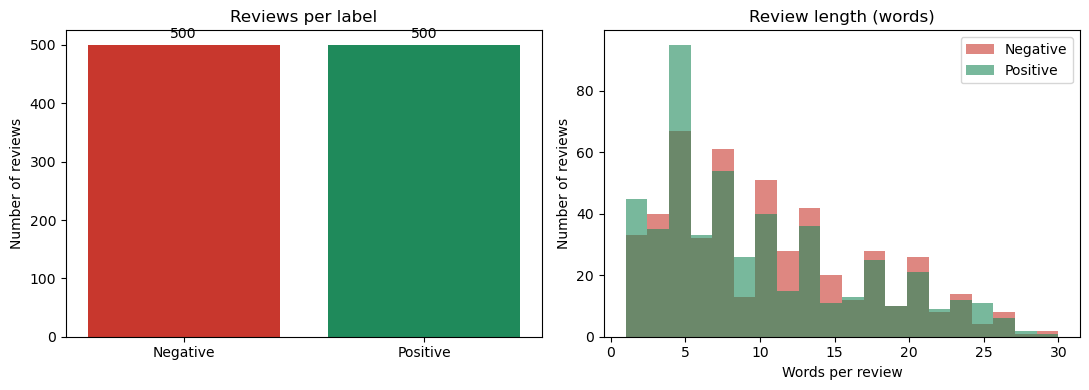


Random sample reviews (3 per label):


,label,review
743,Negative,"Bought mainly for the charger, which broke soo..."
151,Negative,"Audio Quality is poor, very poor."
767,Negative,I really wanted the Plantronics 510 to be the ...
592,Positive,THey are so cool!
882,Positive,The only good thing was that it fits comfortab...
245,Positive,Worth every penny.


In [31]:
import csv

import matplotlib.pyplot as plt
import pandas as pd

LABEL_NAMES = {0: "Negative", 1: "Positive"}
LABEL_COLORS = {0: "#c8372d", 1: "#1f8a5b"}

df = pd.read_csv(
    data_file,
    sep="\t",
    header=None,
    names=["review", "label"],
    quoting=csv.QUOTE_NONE,
    encoding="utf-8",
)

#basic overview
print("Dataset shape:", df.shape)

counts = df["label"].value_counts().sort_index()
balance = pd.DataFrame({
    "Label": [LABEL_NAMES.get(label, label) for label in counts.index],
    "Reviews": counts.values,
    "Share": [f"{share:.1%}" for share in counts / len(df)],
}, index=counts.index)
print("\nNumber of reviews per label:")
display(balance)

#data quality
df["review"] = df["review"].str.strip()

quality = pd.Series({
    "Missing reviews": int(df["review"].isna().sum()),
    "Missing labels": int(df["label"].isna().sum()),
    "Empty reviews": int((df["review"] == "").sum()),
    "Duplicate reviews": int(df["review"].duplicated().sum()),
    "Labels outside 0/1": int((~df["label"].isin([0, 1])).sum()),
}, name="Count")
print("\nData quality checks:")
display(quality.to_frame())

#review length
df["words"] = df["review"].fillna("").str.split().str.len()

length_stats = (
    df.groupby("label")["words"]
    .describe()[["count", "mean", "min", "50%", "max"]]
    .rename(index=LABEL_NAMES, columns={"50%": "median"})
    .round(1)
)
print("\nWords per review:")
display(length_stats)

#charts
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

bars = axes[0].bar(
    [LABEL_NAMES.get(label, label) for label in counts.index],
    counts.values,
    color=[LABEL_COLORS.get(label, "gray") for label in counts.index],
)
axes[0].bar_label(bars, padding=3)
axes[0].set_title("Reviews per label")
axes[0].set_ylabel("Number of reviews")

for label in sorted(df["label"].dropna().unique()):
    axes[1].hist(
        df.loc[df["label"] == label, "words"],
        bins=20,
        alpha=0.6,
        label=LABEL_NAMES.get(label, label),
        color=LABEL_COLORS.get(label, "gray"),
    )
axes[1].set_title("Review length (words)")
axes[1].set_xlabel("Words per review")
axes[1].set_ylabel("Number of reviews")
axes[1].legend()

fig.tight_layout()
plt.show()

#sample reviews
print("\nRandom sample reviews (3 per label):")
samples = (
    df.groupby("label", group_keys=False)
    .sample(n=3, random_state=42)
    .assign(label=lambda d: d["label"].map(LABEL_NAMES))
    [["label", "review"]]
)
display(samples)

## 2.1 Data cleaning




In [32]:
import re
import unicodedata

import pandas as pd

LABEL_NAMES = {0: "Negative", 1: "Positive"}

# Keep the original df unchanged. Only the two data columns are needed.
clean_df = df[["review", "label"]].copy()
steps = [("Original rows", len(clean_df))]


def tidy_spaces(text):
    """Collapse repeated whitespace; keep all words and punctuation."""
    return re.sub(r"\s+", " ", text).strip()


def make_key(text):
    """Comparison key: ignores case, punctuation and Unicode variants."""
    text = unicodedata.normalize("NFKC", text).casefold()
    text = re.sub(r"[^\w\s]", " ", text)
    return re.sub(r"\s+", " ", text).strip()


#1.Missing values.
clean_df = clean_df.dropna(subset=["review", "label"]).copy()
steps.append(("After removing missing values", len(clean_df)))

#2.Whitespace cleanup, then empty reviews.
clean_df["review"] = clean_df["review"].astype(str).map(tidy_spaces)
clean_df = clean_df[clean_df["review"] != ""].copy()
steps.append(("After removing empty reviews", len(clean_df)))

# 3.Labels must be 0 or 1.
invalid_labels = ~clean_df["label"].isin([0, 1])
if invalid_labels.any():
    raise ValueError(f"Unexpected label found in {int(invalid_labels.sum())} rows.")
clean_df["label"] = clean_df["label"].astype(int)

#4.Comparison key; drop reviews with no letters or digits (e.g. "!!!").
clean_df["review_key"] = clean_df["review"].map(make_key)
clean_df = clean_df[clean_df["review_key"] != ""].copy()
steps.append(("After removing reviews without words", len(clean_df)))

#5.Reviews that appear with conflicting labels. Keep them for inspection.
label_counts = clean_df.groupby("review_key")["label"].nunique()
conflicting_keys = label_counts[label_counts > 1].index
conflict_mask = clean_df["review_key"].isin(conflicting_keys)

conflicts_df = clean_df[conflict_mask].sort_values("review_key")
print("Rows with conflicting labels:", int(conflict_mask.sum()))
if len(conflicts_df):
    display(conflicts_df[["review", "label"]].head(10))

clean_df = clean_df[~conflict_mask].copy()
steps.append(("After removing conflicting labels", len(clean_df)))

#6.Keep one copy of each remaining review.
duplicates = int(clean_df.duplicated(subset="review_key").sum())
print("Repeated rows removed:", duplicates)

clean_df = clean_df.drop_duplicates(subset="review_key").reset_index(drop=True)
steps.append(("After removing repeated reviews", len(clean_df)))

#summary
report = pd.DataFrame(steps, columns=["Step", "Rows"])
report["Removed"] = (-report["Rows"].diff()).fillna(0).astype(int)
print("\nCleaning summary:")
display(report)

print("Original reviews:", len(df))
print("Reviews after cleaning:", len(clean_df))

final_counts = clean_df["label"].value_counts().sort_index()
final_balance = pd.DataFrame({
    "Label": [LABEL_NAMES[label] for label in final_counts.index],
    "Reviews": final_counts.values,
    "Share": [f"{share:.1%}" for share in final_counts / len(clean_df)],
}, index=final_counts.index)
print("\nLabels after cleaning:")
display(final_balance)

#Save the cleaned data next to the raw file for later notebooks.
clean_path = data_file.parent / "amazon_cells_clean.csv"
clean_df[["review", "label"]].to_csv(clean_path, index=False, encoding="utf-8")
print("Saved:", clean_path)

Rows with conflicting labels: 0
Repeated rows removed: 17

Cleaning summary:


,Step,Rows,Removed
0,Original rows,1000,0
1,After removing missing values,1000,0
2,After removing empty reviews,1000,0
3,After removing reviews without words,1000,0
4,After removing conflicting labels,1000,0
5,After removing repeated reviews,983,17


Original reviews: 1000
Reviews after cleaning: 983

Labels after cleaning:


,Label,Reviews,Share
label,,,
0,Negative,494,50.3%
1,Positive,489,49.7%


Saved: C:\Users\Mohammad\Desktop\Fith_Semister\Profesional Training\assignment\PT22026\ali081\data\amazon_cells_clean.csv


## 2.2 Training, validation, and test splits




,Set,Reviews,Share of data,Negative,Positive,Positive share
0,Training,688,70.0%,346,342,49.7%
1,Validation,147,15.0%,74,73,49.7%
2,Test,148,15.1%,74,74,50.0%


Verified: no duplicate reviews shared between sets.


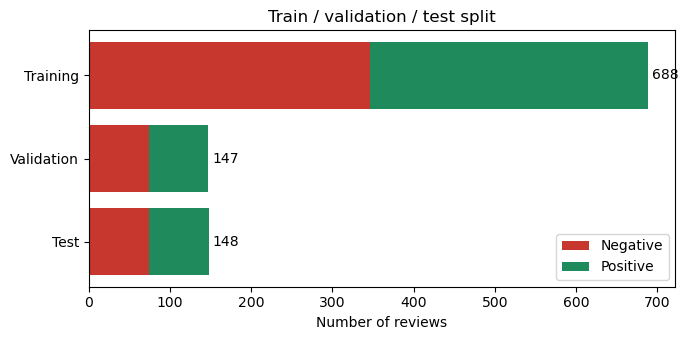

All three datasets and split_info.json saved to: C:\Users\Mohammad\Desktop\Fith_Semister\Profesional Training\assignment\PT22026\ali081\data


In [33]:
import json

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.model_selection import train_test_split

SEED = 42
TRAIN_SIZE = 0.70
VAL_SIZE = 0.15
TEST_SIZE = 0.15

assert abs(TRAIN_SIZE + VAL_SIZE + TEST_SIZE - 1.0) < 1e-9, "Split sizes must add up to 1."
assert clean_df["review_key"].is_unique, "Duplicate review keys found: clean the data first."

# Reserve part of the data for validation and testing.
train_df, remaining_df = train_test_split(
    clean_df,
    test_size=VAL_SIZE + TEST_SIZE,
    random_state=SEED,
    stratify=clean_df["label"],
)

# Divide the remainder into validation and test sets.
val_df, test_df = train_test_split(
    remaining_df,
    test_size=TEST_SIZE / (VAL_SIZE + TEST_SIZE),
    random_state=SEED,
    stratify=remaining_df["label"],
)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

parts = [("Training", train_df), ("Validation", val_df), ("Test", test_df)]

#checks
assert len(train_df) + len(val_df) + len(test_df) == len(clean_df), \
    "Some reviews were lost or duplicated during the split."

train_keys = set(train_df["review_key"])
val_keys = set(val_df["review_key"])
test_keys = set(test_df["review_key"])

assert train_keys.isdisjoint(val_keys), "Training and validation share reviews."
assert train_keys.isdisjoint(test_keys), "Training and test share reviews."
assert val_keys.isdisjoint(test_keys), "Validation and test share reviews."

#summary
summary = pd.DataFrame([
    {
        "Set": name,
        "Reviews": len(part),
        "Share of data": f"{len(part) / len(clean_df):.1%}",
        "Negative": int((part["label"] == 0).sum()),
        "Positive": int((part["label"] == 1).sum()),
        "Positive share": f"{(part['label'] == 1).mean():.1%}",
    }
    for name, part in parts
])
display(summary)
print("Verified: no duplicate reviews shared between sets.")

#chart
fig, ax = plt.subplots(figsize=(7, 3.5))
names = [name for name, _ in parts]
negatives = [int((part["label"] == 0).sum()) for _, part in parts]
positives = [int((part["label"] == 1).sum()) for _, part in parts]

ax.barh(names, negatives, color="#c8372d", label="Negative")
ax.barh(names, positives, left=negatives, color="#1f8a5b", label="Positive")
for i, (neg, pos) in enumerate(zip(negatives, positives)):
    ax.text(neg + pos + 5, i, f"{neg + pos}", va="center")
ax.invert_yaxis()
ax.set_xlabel("Number of reviews")
ax.set_title("Train / validation / test split")
ax.legend(loc="lower right")
fig.tight_layout()
plt.show()

#save
for name, part in [("train", train_df), ("validation", val_df), ("test", test_df)]:
    part[["review", "label"]].to_csv(data_dir / f"{name}.csv", index=False)

split_info = {
    "seed": SEED,
    "ratios": {"train": TRAIN_SIZE, "validation": VAL_SIZE, "test": TEST_SIZE},
    "sizes": {name.lower(): len(part) for name, part in parts},
    "total_reviews": len(clean_df),
    "stratified_by": "label",
}
(data_dir / "split_info.json").write_text(
    json.dumps(split_info, indent=2), encoding="utf-8"
)

print("All three datasets and split_info.json saved to:", data_dir)

## 2.3 Baseline classifiers




In [35]:
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline


def make_vectorizer(**overrides):
    """Same text features for every model, unless overridden on purpose."""
    settings = dict(lowercase=True, ngram_range=(1, 2), stop_words=None)
    settings.update(overrides)
    return TfidfVectorizer(**settings)


def make_pipeline(classifier, **vectorizer_overrides):
    return Pipeline([
        ("tfidf", make_vectorizer(**vectorizer_overrides)),
        ("classifier", classifier),
    ])


models = {
    "Naive Bayes": make_pipeline(MultinomialNB(alpha=1.0)),

    "Logistic Regression": make_pipeline(
        LogisticRegression(max_iter=1000, random_state=SEED)
    ),

    # Setup similar to the final version 2 model, for comparison.
    "Logistic Regression (v2 setup)": make_pipeline(
        LogisticRegression(
            C=10.0, solver="liblinear", max_iter=2000, random_state=SEED
        ),
        sublinear_tf=True,
        min_df=2,
        max_features=100_000,
    ),
}

# Small search grids for a later GridSearchCV run on the training set only.
param_grids = {
    "Naive Bayes": {
        "tfidf__ngram_range": [(1, 1), (1, 2)],
        "classifier__alpha": [0.1, 0.5, 1.0],
    },
    "Logistic Regression": {
        "tfidf__ngram_range": [(1, 1), (1, 2)],
        "classifier__C": [0.1, 1.0, 10.0],
    },
}

#settings overview
overview = pd.DataFrame([
    {
        "Model": name,
        "Classifier": type(pipe.named_steps["classifier"]).__name__,
        "N-grams": pipe.named_steps["tfidf"].ngram_range,
        "Sublinear TF": pipe.named_steps["tfidf"].sublinear_tf,
        "Min doc freq": pipe.named_steps["tfidf"].min_df,
    }
    for name, pipe in models.items()
])
display(overview)

print(f"{len(models)} Both model pipelines are ready.")

,Model,Classifier,N-grams,Sublinear TF,Min doc freq
0,Naive Bayes,MultinomialNB,"(1, 2)",False,1
1,Logistic Regression,LogisticRegression,"(1, 2)",False,1
2,Logistic Regression (v2 setup),LogisticRegression,"(1, 2)",True,2


3 Both model pipelines are ready.


## 2.4 Validation comparison




Naive Bayes: training completed.
Logistic Regression: training completed.
Logistic Regression (v2 setup): training completed.


,Model,Train accuracy,Validation accuracy,Overfit gap,Macro precision,Macro recall,Macro F1,CV Macro F1 (mean),CV Macro F1 (std),Training seconds
0,Logistic Regression,0.9985,0.8299,0.1686,0.8305,0.8298,0.8298,0.7994,0.0364,0.0453
1,Naive Bayes,0.9971,0.8231,0.1740,0.8269,0.8235,0.8227,0.8018,0.0394,0.0498
2,Logistic Regression (v2 setup),0.9985,0.8027,0.1958,0.8028,0.8027,0.8027,0.7978,0.0302,0.0526



Best on validation: Logistic Regression (Macro F1 0.8298, CV 0.7994 +/- 0.0364).
Validation set size: 147 reviews (one review = 0.68%).


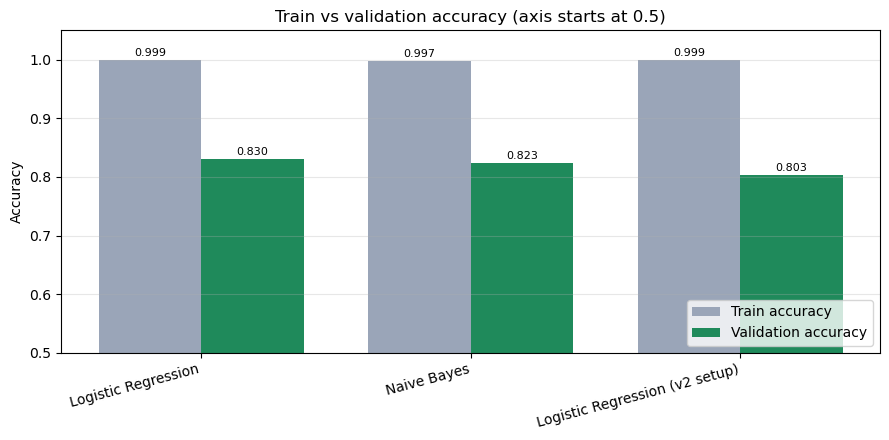

Validation results saved to: C:\Users\Mohammad\Desktop\Fith_Semister\Profesional Training\assignment\PT22026\ali081\results


In [36]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from time import perf_counter

from sklearn.base import clone
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score
from sklearn.model_selection import StratifiedKFold, cross_val_score

X_train, y_train = train_df["review"], train_df["label"]
X_val, y_val = val_df["review"], val_df["label"]

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

rows = []
val_predictions = {}  # kept for confusion matrices and error analysis later

for name, model in models.items():
    try:
        # Cross-validation on the training set only (uses fresh copies).
        cv_scores = cross_val_score(
            clone(model), X_train, y_train, cv=cv, scoring="f1_macro"
        )

        # Learn only from training data.
        start = perf_counter()
        model.fit(X_train, y_train)
        training_seconds = perf_counter() - start

        train_pred = model.predict(X_train)
        val_pred = model.predict(X_val)
        val_predictions[name] = val_pred

        train_acc = accuracy_score(y_train, train_pred)
        val_acc = accuracy_score(y_val, val_pred)

        rows.append({
            "Model": name,
            "Train accuracy": train_acc,
            "Validation accuracy": val_acc,
            "Overfit gap": train_acc - val_acc,
            "Macro precision": precision_score(y_val, val_pred, average="macro", zero_division=0),
            "Macro recall": recall_score(y_val, val_pred, average="macro", zero_division=0),
            "Macro F1": f1_score(y_val, val_pred, average="macro", zero_division=0),
            "CV Macro F1 (mean)": cv_scores.mean(),
            "CV Macro F1 (std)": cv_scores.std(),
            "Training seconds": training_seconds,
        })
        print(f"{name}: training completed.")

    except Exception as error:
        print(f"{name}: FAILED ({type(error).__name__}: {error})")

comparison_df = (
    pd.DataFrame(rows)
    .sort_values(["Macro F1", "Validation accuracy"], ascending=False)
    .reset_index(drop=True)
)

display(comparison_df.round(4))

best = comparison_df.iloc[0]
print(
    f"\nBest on validation: {best['Model']} "
    f"(Macro F1 {best['Macro F1']:.4f}, CV {best['CV Macro F1 (mean)']:.4f} "
    f"+/- {best['CV Macro F1 (std)']:.4f})."
)
print(f"Validation set size: {len(y_val)} reviews (one review = {1 / len(y_val):.2%}).")

#chart
fig, ax = plt.subplots(figsize=(9, 4.5))
x = np.arange(len(comparison_df))
width = 0.38

train_bars = ax.bar(x - width / 2, comparison_df["Train accuracy"], width,
                    label="Train accuracy", color="#9aa5b8")
val_bars = ax.bar(x + width / 2, comparison_df["Validation accuracy"], width,
                  label="Validation accuracy", color="#1f8a5b")
ax.bar_label(train_bars, fmt="%.3f", padding=2, fontsize=8)
ax.bar_label(val_bars, fmt="%.3f", padding=2, fontsize=8)

ax.set_xticks(x)
ax.set_xticklabels(comparison_df["Model"], rotation=15, ha="right")
ax.set_ylim(0.5, 1.05)
ax.set_ylabel("Accuracy")
ax.set_title("Train vs validation accuracy (axis starts at 0.5)")
ax.legend(loc="lower right")
ax.grid(axis="y", alpha=0.3)
fig.tight_layout()

results_dir = project_dir / "results"
results_dir.mkdir(exist_ok=True)
fig.savefig(results_dir / "validation_comparison.png", dpi=200, bbox_inches="tight")
plt.show()

comparison_df.to_csv(results_dir / "validation_comparison.csv", index=False)
print("Validation results saved to:", results_dir)

## 2.5 Final baseline evaluation




Selected model: Logistic Regression
Final training reviews: 835
Test reviews: 148
Test accuracy: 80.41%  (95% CI 73.65% to 86.49%)
Test Macro F1: 0.8036
One test review = 0.68% of accuracy.

Classification report:
              precision    recall  f1-score   support

    Negative     0.8358    0.7568    0.7943        74
    Positive     0.7778    0.8514    0.8129        74

    accuracy                         0.8041       148
   macro avg     0.8068    0.8041    0.8036       148
weighted avg     0.8068    0.8041    0.8036       148



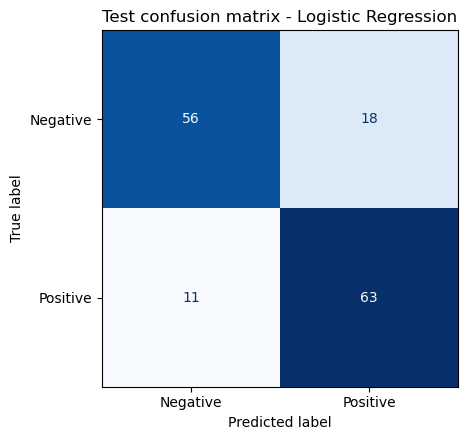

29 test mistakes saved to test_errors.csv


,review,true,predicted,confidence
89,"The loudspeaker option is great, the bumpers w...",Negative,Positive,0.820645
83,Very Displeased.,Negative,Positive,0.717174
41,If you are Razr owner...you must have this!,Positive,Negative,0.665059
58,It definitely was not as good as my S11.,Positive,Negative,0.647276
132,Phone now holds charge like it did when it was...,Positive,Negative,0.606188


Existing model backed up to: sentiment_pipeline_backup_20261112_142230.joblib
Reload check passed.
Model and test results saved to: C:\Users\Mohammad\Desktop\Fith_Semister\Profesional Training\assignment\PT22026\ali081\results


In [37]:
import json
import shutil
from datetime import datetime

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.base import clone
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    f1_score,
)

LABELS = [0, 1]
LABEL_NAMES = ["Negative", "Positive"]

models_dir = project_dir / "models"
results_dir = project_dir / "results"
models_dir.mkdir(exist_ok=True)
results_dir.mkdir(exist_ok=True)

#select on validation only
best_name = comparison_df.iloc[0]["Model"]
final_model = clone(models[best_name])

# Combine training and validation data, then fit once.
development_df = pd.concat([train_df, val_df], ignore_index=True)
final_model.fit(development_df["review"], development_df["label"])

# evaluate once on the test set
X_test = test_df["review"]
y_test = test_df["label"].to_numpy()
test_predictions = final_model.predict(X_test)

test_accuracy = accuracy_score(y_test, test_predictions)
test_macro_f1 = f1_score(y_test, test_predictions, average="macro", zero_division=0)

# 95% bootstrap confidence interval for accuracy.
rng = np.random.default_rng(SEED)
correct = (y_test == test_predictions).astype(float)
picks = rng.integers(0, len(correct), size=(1000, len(correct)))
ci_low, ci_high = np.percentile(correct[picks].mean(axis=1), [2.5, 97.5])

print("Selected model:", best_name)
print("Final training reviews:", len(development_df))
print("Test reviews:", len(test_df))
print(f"Test accuracy: {test_accuracy:.2%}  (95% CI {ci_low:.2%} to {ci_high:.2%})")
print(f"Test Macro F1: {test_macro_f1:.4f}")
print(f"One test review = {1 / len(test_df):.2%} of accuracy.")

report_text = classification_report(
    y_test,
    test_predictions,
    labels=LABELS,
    target_names=LABEL_NAMES,
    digits=4,
    zero_division=0,
)
print("\nClassification report:")
print(report_text)

# confusion matrix plot
fig, ax = plt.subplots(figsize=(5.5, 4.5))
ConfusionMatrixDisplay.from_predictions(
    y_test, test_predictions, labels=LABELS, display_labels=LABEL_NAMES,
    cmap="Blues", colorbar=False, ax=ax,
)
ax.set_title(f"Test confusion matrix - {best_name}")
fig.tight_layout()
fig.savefig(results_dir / "test_confusion_matrix.png", dpi=200, bbox_inches="tight")
plt.show()

# test-set mistakes
errors = pd.DataFrame({
    "review": X_test.to_numpy(),
    "true": [LABEL_NAMES[LABELS.index(v)] for v in y_test],
    "predicted": [LABEL_NAMES[LABELS.index(v)] for v in test_predictions],
})
if hasattr(final_model, "predict_proba"):
    probabilities = final_model.predict_proba(X_test)
    errors["confidence"] = probabilities.max(axis=1)
errors = errors[test_predictions != y_test]
if "confidence" in errors:
    errors = errors.sort_values("confidence", ascending=False)

errors.to_csv(results_dir / "test_errors.csv", index=False)
print(f"{len(errors)} test mistakes saved to test_errors.csv")
display(errors.head(5).assign(review=lambda d: d["review"].str.slice(0, 120)))

# save the whole pipeline
model_path = models_dir / "sentiment_pipeline.joblib"
if model_path.exists():
    stamp = datetime.now().strftime("%Y%m%d_%H%M%S")
    backup_path = models_dir / f"sentiment_pipeline_backup_{stamp}.joblib"
    shutil.copy2(model_path, backup_path)
    print("Existing model backed up to:", backup_path.name)

joblib.dump(final_model, model_path)

# Reload check: the saved file must give identical predictions.
reloaded = joblib.load(model_path)
assert (reloaded.predict(X_test) == test_predictions).all(), "Saved model differs!"
print("Reload check passed.")

# save the results
metrics = {
    "selected_model": best_name,
    "selection_metric": "validation macro F1",
    "final_training_reviews": len(development_df),
    "test_reviews": len(test_df),
    "test_accuracy": float(test_accuracy),
    "test_accuracy_95ci": [float(ci_low), float(ci_high)],
    "test_macro_f1": float(test_macro_f1),
    "seed": SEED,
    "scikit_learn_version": sklearn.__version__,
    "classifier": type(final_model.steps[-1][1]).__name__,
    "classifier_params": {
        k: str(v) for k, v in final_model.steps[-1][1].get_params().items()
    },
    "vectorizer_ngram_range": list(final_model.named_steps["tfidf"].ngram_range),
    "created": datetime.now().isoformat(timespec="seconds"),
}

(results_dir / "test_metrics.json").write_text(
    json.dumps(metrics, indent=2), encoding="utf-8"
)
(results_dir / "test_classification_report.txt").write_text(
    report_text, encoding="utf-8"
)

print("Model and test results saved to:", results_dir)

## 2.6 Confusion matrix




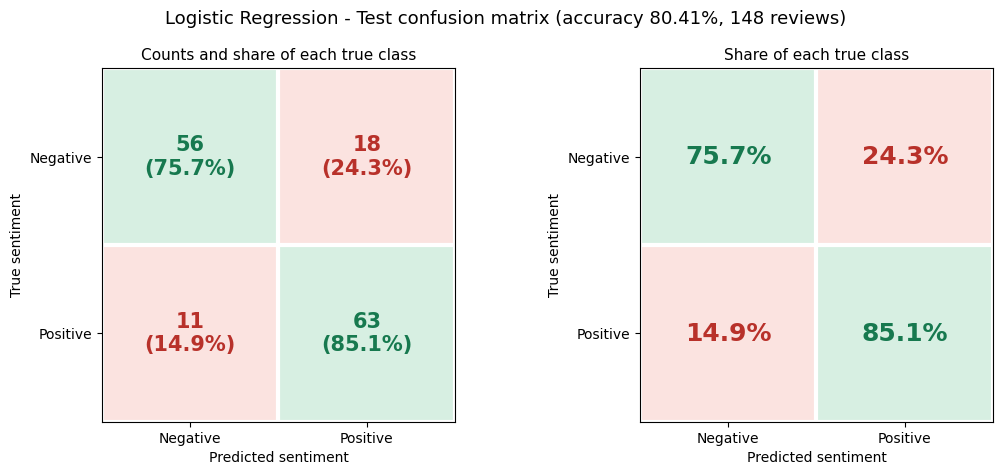

Correct: 119 of 148 reviews.
Negative reviews predicted as positive: 18 (24.3% of negative reviews)
Positive reviews predicted as negative: 11 (14.9% of positive reviews)


In [38]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import ListedColormap
from sklearn.metrics import accuracy_score, confusion_matrix

LABELS = [0, 1]
LABEL_NAMES = ["Negative", "Positive"]

y_true = np.asarray(test_df["label"])
y_pred = np.asarray(test_predictions)
assert len(y_true) == len(y_pred), "Labels and predictions have different lengths."

counts = confusion_matrix(y_true, y_pred, labels=LABELS)
row_share = counts / counts.sum(axis=1, keepdims=True)  # share of each true class
accuracy = accuracy_score(y_true, y_pred)

# Green for correct predictions (diagonal), red tint for mistakes.
correct_mask = np.eye(2, dtype=bool)
tint = np.where(correct_mask, 1.0, 0.0)
cmap = ListedColormap(["#fbe3e0", "#d7efe2"])

fig, axes = plt.subplots(1, 2, figsize=(11, 4.8))

for ax, title in zip(axes, ["Counts and share of each true class", "Share of each true class"]):
    ax.imshow(tint, cmap=cmap, vmin=0, vmax=1)
    ax.set_xticks(range(2))
    ax.set_yticks(range(2))
    ax.set_xticklabels(LABEL_NAMES)
    ax.set_yticklabels(LABEL_NAMES)
    ax.set_xlabel("Predicted sentiment")
    ax.set_ylabel("True sentiment")
    ax.set_title(title, fontsize=11)
    ax.set_xticks(np.arange(-0.5, 2, 1), minor=True)
    ax.set_yticks(np.arange(-0.5, 2, 1), minor=True)
    ax.grid(which="minor", color="white", linewidth=3)
    ax.tick_params(which="minor", length=0)

for i in range(2):
    for j in range(2):
        color = "#17794f" if i == j else "#b8312a"
        axes[0].text(j, i, f"{counts[i, j]}\n({row_share[i, j]:.1%})",
                     ha="center", va="center", fontsize=15, fontweight="bold", color=color)
        axes[1].text(j, i, f"{row_share[i, j]:.1%}",
                     ha="center", va="center", fontsize=18, fontweight="bold", color=color)

fig.suptitle(f"{best_name} - Test confusion matrix (accuracy {accuracy:.2%}, {len(y_true)} reviews)",
             fontsize=13)
fig.tight_layout()

results_dir.mkdir(exist_ok=True)
fig.savefig(results_dir / "test_confusion_matrix.png", dpi=200, bbox_inches="tight")
plt.show()

# -- error summary
false_positive = counts[0, 1]  # truly negative, predicted positive
false_negative = counts[1, 0]  # truly positive, predicted negative
print(f"Correct: {counts[0, 0] + counts[1, 1]} of {len(y_true)} reviews.")
print(f"Negative reviews predicted as positive: {false_positive} "
      f"({row_share[0, 1]:.1%} of negative reviews)")
print(f"Positive reviews predicted as negative: {false_negative} "
      f"({row_share[1, 0]:.1%} of positive reviews)")

## 2.7 Error inspection




Total mistakes: 29 of 148 test reviews

Negative reviews predicted as positive (most confident first):


C:\Users\Mohammad\AppData\Local\Temp\ipykernel_24944\164837358.py:45: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  test_analysis["Has negation"] = test_analysis["review"].str.contains(NEGATION)
C:\Users\Mohammad\AppData\Local\Temp\ipykernel_24944\164837358.py:46: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  test_analysis["Has contrast"] = test_analysis["review"].str.contains(CONTRAST)


,review,Actual,Predicted,Confidence,Main drivers
89,"The loudspeaker option is great, the bumpers with the lights is very ... appealing.",Negative,Positive,0.821,"great (+0.7), is great (+0.3), very (+0.3)"
83,Very Displeased.,Negative,Positive,0.717,very (+1.1)
59,"I have this phone and it is a thorn in my side, I really abhor it.",Negative,Positive,0.595,"and (+0.2), phone (+0.1), is (+0.1)"
94,i got this phone around the end of may and i'm completely unhappy with it.,Negative,Positive,0.581,"and (+0.2), got (+0.1), with (+0.1)"
37,Used and dirty.,Negative,Positive,0.577,"and (+0.4), used and (+0.1), used (+0.0)"



Positive reviews predicted as negative (most confident first):


,review,Actual,Predicted,Confidence,Main drivers
41,If you are Razr owner...you must have this!,Positive,Negative,0.665,"you (-0.3), if (-0.2), if you (-0.1)"
58,It definitely was not as good as my S11.,Positive,Negative,0.647,"not (-0.5), good (+0.4), as (-0.2)"
132,Phone now holds charge like it did when it was new.,Positive,Negative,0.606,"charge (-0.1), phone (+0.1), was (-0.1)"
72,Its a total package.,Positive,Negative,0.571,its (-0.1)
88,I have yet to run this new battery below two bars and that's three days without charging.,Positive,Negative,0.550,"and (+0.2), days (-0.1), without (+0.1)"



Are mistakes more common with negation or contrast words?


,Pattern,Mistakes with pattern,Share of mistakes,Share of all test reviews
0,Has negation,4,13.8%,14.9%
1,Has contrast,2,6.9%,6.1%


Average words per review - correct: 10.1 | mistakes: 10.5


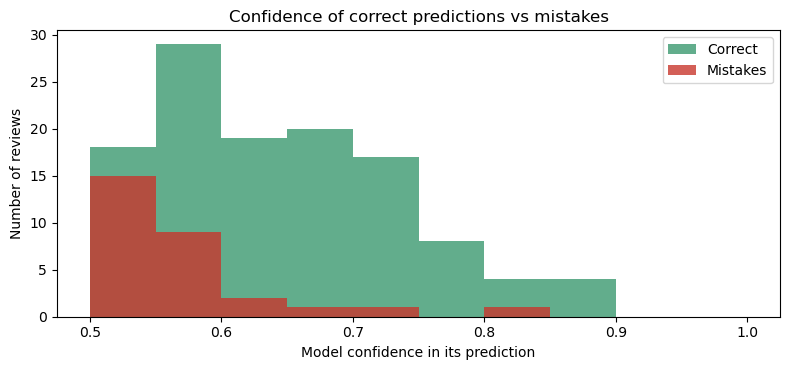

Mistakes saved for analysis.


In [39]:
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

LABEL_NAMES = {0: "Negative", 1: "Positive"}

vectorizer = final_model.named_steps["tfidf"]
classifier = final_model.steps[-1][1]
feature_names = vectorizer.get_feature_names_out()

# Per-feature weight for the positive class (Logistic Regression or Naive Bayes).
if hasattr(classifier, "coef_"):
    weights = classifier.coef_[0]
elif hasattr(classifier, "feature_log_prob_"):
    weights = classifier.feature_log_prob_[1] - classifier.feature_log_prob_[0]
else:
    weights = None


def top_drivers(text, n=3):
    """Words or phrases that pushed the prediction the most."""
    if weights is None:
        return ""
    row = vectorizer.transform([text]).tocsr()
    push = row.data * weights[row.indices]
    order = np.argsort(-np.abs(push))[:n]
    return ", ".join(f"{feature_names[row.indices[i]]} ({push[i]:+.1f})" for i in order)


NEGATION = re.compile(r"\b(not|no|never|cannot|without)\b|n['’]t\b", re.I)
CONTRAST = re.compile(r"\b(but|however|although|though|yet)\b", re.I)

# ------------------------------------------------ match reviews and predictions
test_analysis = test_df[["review", "label"]].copy().reset_index(drop=True)
test_analysis["predicted_label"] = np.asarray(test_predictions)
test_analysis["Actual"] = test_analysis["label"].map(LABEL_NAMES)
test_analysis["Predicted"] = test_analysis["predicted_label"].map(LABEL_NAMES)
test_analysis["is_mistake"] = test_analysis["label"] != test_analysis["predicted_label"]

if hasattr(final_model, "predict_proba"):
    test_analysis["Confidence"] = final_model.predict_proba(test_analysis["review"]).max(axis=1)

test_analysis["Has negation"] = test_analysis["review"].str.contains(NEGATION)
test_analysis["Has contrast"] = test_analysis["review"].str.contains(CONTRAST)
test_analysis["Words"] = test_analysis["review"].str.split().str.len()

mistakes = test_analysis[test_analysis["is_mistake"]].copy()
mistakes["Main drivers"] = mistakes["review"].map(top_drivers)
if "Confidence" in mistakes:
    mistakes = mistakes.sort_values("Confidence", ascending=False)

print("Total mistakes:", len(mistakes), "of", len(test_analysis), "test reviews")

columns = ["review", "Actual", "Predicted"]
if "Confidence" in mistakes:
    columns.append("Confidence")
columns.append("Main drivers")

# ------------------------------------------- examples of both kinds of mistake
with pd.option_context("display.max_colwidth", None):
    print("\nNegative reviews predicted as positive (most confident first):")
    display(mistakes[mistakes["label"] == 0][columns].head(5).round(3))

    print("\nPositive reviews predicted as negative (most confident first):")
    display(mistakes[mistakes["label"] == 1][columns].head(5).round(3))

# --------------------------------------------------------- pattern comparison
patterns = pd.DataFrame([
    {
        "Pattern": pattern,
        "Mistakes with pattern": int(mistakes[pattern].sum()),
        "Share of mistakes": mistakes[pattern].mean() if len(mistakes) else 0.0,
        "Share of all test reviews": test_analysis[pattern].mean(),
    }
    for pattern in ["Has negation", "Has contrast"]
])
patterns["Share of mistakes"] = patterns["Share of mistakes"].map("{:.1%}".format)
patterns["Share of all test reviews"] = patterns["Share of all test reviews"].map("{:.1%}".format)
print("\nAre mistakes more common with negation or contrast words?")
display(patterns)

avg_len = test_analysis.groupby("is_mistake")["Words"].mean().round(1)
print("Average words per review - correct:", avg_len.get(False), "| mistakes:", avg_len.get(True))

# --------------------------------------------------- confidence chart
if "Confidence" in test_analysis:
    fig, ax = plt.subplots(figsize=(8, 3.8))
    bins = np.linspace(0.5, 1.0, 11)
    ax.hist(test_analysis.loc[~test_analysis["is_mistake"], "Confidence"],
            bins=bins, alpha=0.7, color="#1f8a5b", label="Correct")
    ax.hist(test_analysis.loc[test_analysis["is_mistake"], "Confidence"],
            bins=bins, alpha=0.8, color="#c8372d", label="Mistakes")
    ax.set_xlabel("Model confidence in its prediction")
    ax.set_ylabel("Number of reviews")
    ax.set_title("Confidence of correct predictions vs mistakes")
    ax.legend()
    fig.tight_layout()
    fig.savefig(results_dir / "test_confidence_hist.png", dpi=200, bbox_inches="tight")
    plt.show()

# Keep review-level data in the ignored data folder.
mistakes.drop(columns=["is_mistake"]).to_csv(
    data_dir / "test_misclassifications.csv", index=False
)
print("Mistakes saved for analysis.")

## 3. Diagnostic examples

These examples illustrate behavior; they are not a representative test set. Neutral, mixed, and unrelated inputs are outside the binary product-review task.


Category,Review,Expected meaning,Prediction,Result,Positive estimate,Negative estimate,Note
Clear sentiment,This headset works perfectly. I love it.,Positive,Positive,✅ Correct,0.787,0.213,
Clear sentiment,The charger broke after one day. Terrible quality.,Negative,Negative,✅ Correct,0.329,0.671,
Clear sentiment,The sound quality is excellent.,Positive,Positive,✅ Correct,0.758,0.242,
Clear sentiment,I am happy with this purchase.,Positive,Positive,✅ Correct,0.658,0.342,
Clear sentiment,I am disappointed with this purchase.,Negative,Negative,✅ Correct,0.423,0.577,Uncertain (close scores)
Negation,The sound quality is not good.,Negative,Positive,❌ Wrong,0.530,0.470,Uncertain (close scores)
Negation,The battery does not last long.,Negative,Negative,✅ Correct,0.204,0.796,
Negation,"This is not bad at all, I would buy it again.",Positive,Negative,❌ Wrong,0.296,0.704,
Beyond two classes,The phone arrived this morning.,Neutral / factual,Negative,ℹ️ Info only,0.464,0.536,Uncertain (close scores)
Beyond two classes,"The sound is great, but the battery is terrible.",Mixed,Positive,ℹ️ Info only,0.578,0.422,Uncertain (close scores)



Testable checks passed: 6 of 8


,passed,total
Category,,
Clear sentiment,5,5
Negation,1,3


Info-only rows (neutral, mixed, out of scope) have no correct answer for a two-class model. Check that they are flagged as uncertain or handled sensibly, but do not count them as errors.


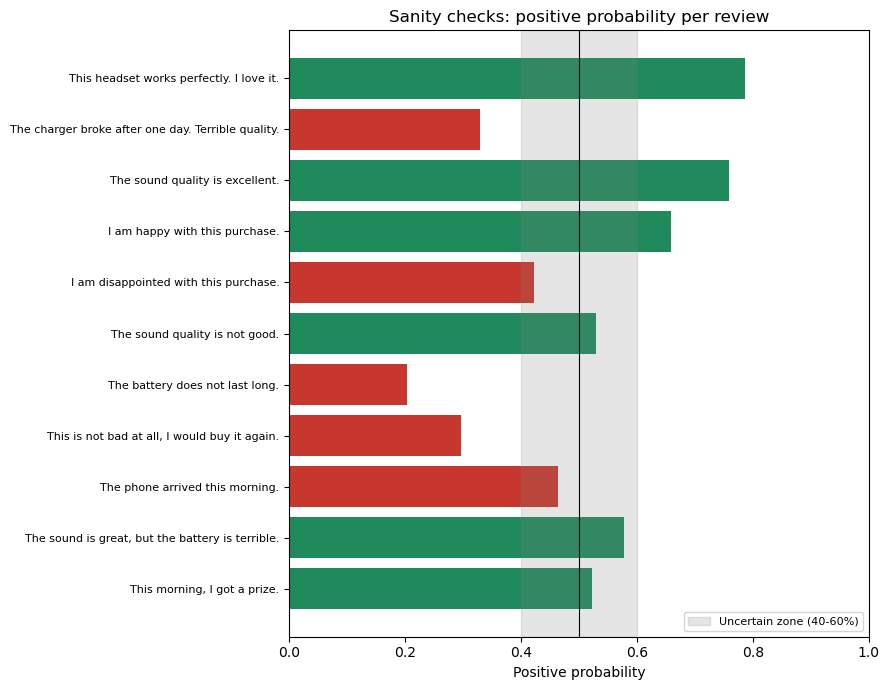

Saved: C:\Users\Mohammad\Desktop\Fith_Semister\Profesional Training\assignment\PT22026\ali081\results\sanity_checks.csv


In [40]:
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

UNCERTAINTY_THRESHOLD = 0.60  # same display rule as the app (not calibrated)
MODEL_PATH = Path.cwd() / "models" / "sentiment_pipeline.joblib"

if not MODEL_PATH.exists():
    raise FileNotFoundError(f"Model not found: {MODEL_PATH}")

loaded_model = joblib.load(MODEL_PATH)
vectorizer = loaded_model.named_steps["tfidf"]

positive_col = list(loaded_model.classes_).index(1)
negative_col = list(loaded_model.classes_).index(0)

# (review, expected meaning, category)
# "Positive"/"Negative" are testable; the other meanings are outside what a
# two-class model can express, so they are shown for information only.
checks = [
    ("This headset works perfectly. I love it.", "Positive", "Clear sentiment"),
    ("The charger broke after one day. Terrible quality.", "Negative", "Clear sentiment"),
    ("The sound quality is excellent.", "Positive", "Clear sentiment"),
    ("I am happy with this purchase.", "Positive", "Clear sentiment"),
    ("I am disappointed with this purchase.", "Negative", "Clear sentiment"),
    ("The sound quality is not good.", "Negative", "Negation"),
    ("The battery does not last long.", "Negative", "Negation"),
    ("This is not bad at all, I would buy it again.", "Positive", "Negation"),
    ("The phone arrived this morning.", "Neutral / factual", "Beyond two classes"),
    ("The sound is great, but the battery is terrible.", "Mixed", "Beyond two classes"),
    ("This morning, I got a prize.", "Outside product-review scope", "Out of scope"),
    ("!!!", "No words", "Out of scope"),
]

texts = [text for text, _, _ in checks]
known = vectorizer.transform(texts).getnnz(axis=1) > 0
probabilities = loaded_model.predict_proba(texts)

rows = []
for (text, expected, category), has_words, probs in zip(checks, known, probabilities):
    p_pos = float(probs[positive_col])
    p_neg = float(probs[negative_col])

    if not has_words:
        prediction, note = "No known words", "Model cannot read this text"
    else:
        prediction = "Positive" if p_pos >= p_neg else "Negative"
        uncertain = max(p_pos, p_neg) < UNCERTAINTY_THRESHOLD
        note = "Uncertain (close scores)" if uncertain else ""

    if expected in ("Positive", "Negative"):
        result = "✅ Correct" if prediction == expected else "❌ Wrong"
    else:
        result = "ℹ️ Info only"

    rows.append({
        "Category": category,
        "Review": text,
        "Expected meaning": expected,
        "Prediction": prediction,
        "Result": result,
        "Positive estimate": round(p_pos, 3) if has_words else np.nan,
        "Negative estimate": round(p_neg, 3) if has_words else np.nan,
        "Note": note,
    })

report = pd.DataFrame(rows)


def colour_result(value):
    if value.startswith("✅"):
        return "background-color: #d7efe2; color: #17583a"
    if value.startswith("❌"):
        return "background-color: #fbe3e0; color: #8f2620"
    return "background-color: #eef1f6; color: #4a5365"


styled = (
    report.style
    .map(colour_result, subset=["Result"])
    .set_properties(**{"white-space": "normal", "text-align": "left"})
    .hide(axis="index")
    .format({"Positive estimate": "{:.3f}", "Negative estimate": "{:.3f}"}, na_rep="-")
)
display(styled)

# summary
testable = report[report["Result"].str.startswith(("✅", "❌"))]
passed = int(testable["Result"].str.startswith("✅").sum())
print(f"\nTestable checks passed: {passed} of {len(testable)}")

by_category = (
    testable.assign(ok=testable["Result"].str.startswith("✅"))
    .groupby("Category")["ok"].agg(passed="sum", total="count")
)
display(by_category)

print(
    "Info-only rows (neutral, mixed, out of scope) have no correct answer for "
    "a two-class model. Check that they are flagged as uncertain or handled "
    "sensibly, but do not count them as errors."
)

# chart
plot_df = report[report["Prediction"] != "No known words"].iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 0.5 * len(plot_df) + 1.5))
colours = ["#1f8a5b" if p >= 0.5 else "#c8372d" for p in plot_df["Positive estimate"]]
ax.barh(range(len(plot_df)), plot_df["Positive estimate"], color=colours)
ax.axvspan(1 - UNCERTAINTY_THRESHOLD, UNCERTAINTY_THRESHOLD, color="gray", alpha=0.2,
           label="Uncertain zone (40-60%)")
ax.axvline(0.5, color="black", linewidth=0.8)
ax.set_yticks(range(len(plot_df)))
ax.set_yticklabels([t if len(t) <= 55 else t[:52] + "..." for t in plot_df["Review"]], fontsize=8)
ax.set_xlim(0, 1)
ax.set_xlabel("Positive probability")
ax.set_title("Sanity checks: positive probability per review")
ax.legend(loc="lower right", fontsize=8)
fig.tight_layout()
plt.show()

results_folder = Path.cwd() / "results"
results_folder.mkdir(exist_ok=True)
report.to_csv(results_folder / "sanity_checks.csv", index=False)
print("Saved:", results_folder / "sanity_checks.csv")

## 3.1 Parameter search on the original training split

Search 18 settings using five-fold cross-validation. The vectorizer stays inside the pipeline to learn vocabulary within each fold. Evaluate the selected candidate on validation data.


Training reviews: 688 | Validation reviews: 147
Comparing 18 settings using 5-fold cross-validation (90 fits)...
Fitting 5 folds for each of 18 candidates, totalling 90 fits

Best settings:
LogisticRegression, n-grams (1, 2), C = 10.0
Best average CV Macro F1: 0.8125 (+/- 0.0356)
18 of 18 settings are within one standard deviation of the best. Differences between them are probably noise.

Top 5 settings:


,Rank,Classifier,N-grams,Setting,CV Macro F1,CV std,CV accuracy,Fit seconds
0,1,LogisticRegression,"(1, 2)",C = 10.0,0.8125,0.0356,0.8126,0.0616
1,2,LogisticRegression,"(1, 3)",C = 10.0,0.8124,0.0363,0.8126,0.0920
2,3,LogisticRegression,"(1, 1)",C = 10.0,0.8110,0.0290,0.8111,0.0340
3,4,LogisticRegression,"(1, 1)",C = 2.0,0.8095,0.0332,0.8097,0.0269
4,5,LogisticRegression,"(1, 2)",C = 0.5,0.8053,0.0375,0.8053,0.0503



Best setting per classifier:


,Rank,Classifier,N-grams,Setting,CV Macro F1,CV std,CV accuracy,Fit seconds
0,1,LogisticRegression,"(1, 2)",C = 10.0,0.8125,0.0356,0.8126,0.0616
1,10,MultinomialNB,"(1, 2)",alpha = 1.0,0.8018,0.0394,0.8024,0.0501



Candidate validation accuracy: 83.67%
Candidate validation Macro F1: 0.8365
(One validation review = 0.68% of accuracy.)


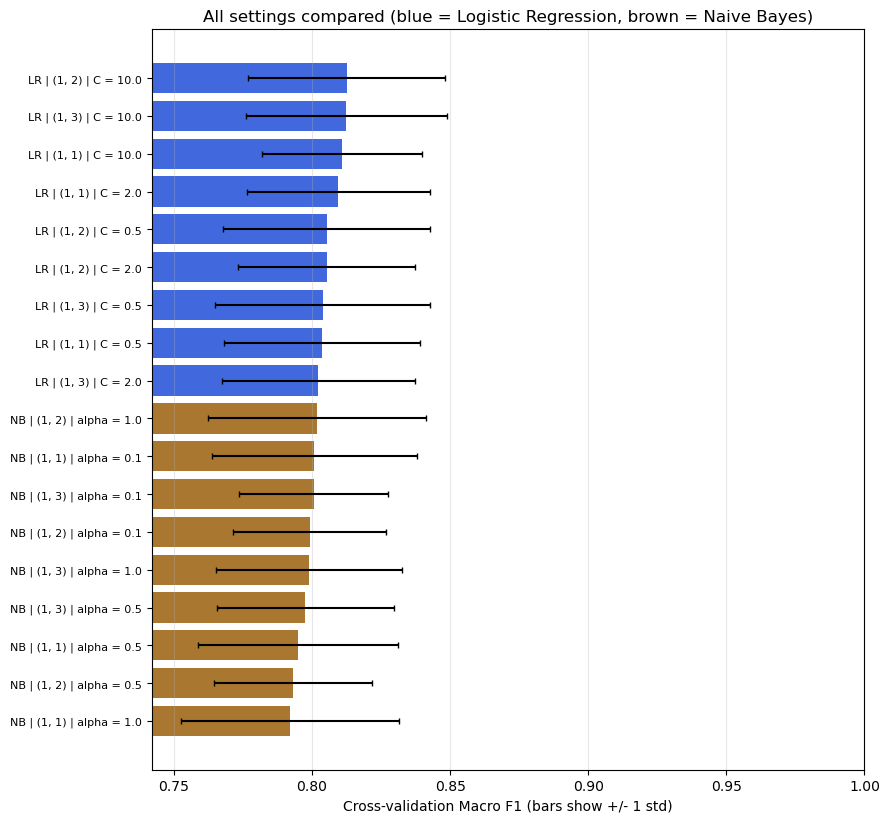

Grid search results saved to: C:\Users\Mohammad\Desktop\Fith_Semister\Profesional Training\assignment\PT22026\ali081\results


In [41]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score
from sklearn.model_selection import GridSearchCV, ParameterGrid, StratifiedKFold
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline

SEED = 42
project_dir = Path.cwd()
data_dir = project_dir / "data"
results_dir = project_dir / "results"
results_dir.mkdir(exist_ok=True)


def load_split(name):
    frame = pd.read_csv(data_dir / f"{name}.csv").dropna(subset=["review", "label"])
    assert {"review", "label"} <= set(frame.columns), f"{name}.csv needs review and label columns."
    return frame


train_data = load_split("train")
validation_data = load_split("validation")
print(f"Training reviews: {len(train_data)} | Validation reviews: {len(validation_data)}")

pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(lowercase=True, stop_words=None)),
    ("classifier", MultinomialNB()),
])

# Try different phrase lengths and classifier settings.
NGRAMS = [(1, 1), (1, 2), (1, 3)]
parameter_grid = [
    {
        "tfidf__ngram_range": NGRAMS,
        "classifier": [MultinomialNB()],
        "classifier__alpha": [0.1, 0.5, 1.0],
    },
    {
        "tfidf__ngram_range": NGRAMS,
        "classifier": [LogisticRegression(max_iter=2000, random_state=SEED)],
        "classifier__C": [0.5, 2.0, 10.0],
    },
]

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

search = GridSearchCV(
    estimator=pipeline,
    param_grid=parameter_grid,
    scoring={"f1_macro": "f1_macro", "accuracy": "accuracy"},
    refit="f1_macro",          # the best setting is chosen by Macro F1
    cv=cv,
    n_jobs=2,
    verbose=1,
    return_train_score=False,
    error_score="raise",
)

n_settings = len(ParameterGrid(parameter_grid))
print(f"Comparing {n_settings} settings using {cv.get_n_splits()}-fold cross-validation "
      f"({n_settings * cv.get_n_splits()} fits)...")

search.fit(train_data["review"], train_data["label"])

#  readable table
def describe(params):
    classifier = params["classifier"]
    name = type(classifier).__name__
    if "classifier__alpha" in params:
        return name, "alpha", params["classifier__alpha"]
    return name, "C", params["classifier__C"]


cv_results = pd.DataFrame(search.cv_results_)
described = cv_results["params"].map(describe)
table = pd.DataFrame({
    "Rank": cv_results["rank_test_f1_macro"],
    "Classifier": [d[0] for d in described],
    "N-grams": cv_results["param_tfidf__ngram_range"].astype(str),
    "Setting": [f"{d[1]} = {d[2]}" for d in described],
    "CV Macro F1": cv_results["mean_test_f1_macro"],
    "CV std": cv_results["std_test_f1_macro"],
    "CV accuracy": cv_results["mean_test_accuracy"],
    "Fit seconds": cv_results["mean_fit_time"],
}).sort_values("Rank").reset_index(drop=True)

best = table.iloc[0]
print("\nBest settings:")
print(f"{best['Classifier']}, n-grams {best['N-grams']}, {best['Setting']}")
print(f"Best average CV Macro F1: {search.best_score_:.4f} (+/- {best['CV std']:.4f})")

# How many settings are tied with the best one?
tied = table[table["CV Macro F1"] >= best["CV Macro F1"] - best["CV std"]]
print(f"{len(tied)} of {n_settings} settings are within one standard deviation of the best. "
      "Differences between them are probably noise.")

print("\nTop 5 settings:")
display(table.head(5).round(4))

print("\nBest setting per classifier:")
display(table.groupby("Classifier").head(1).round(4).reset_index(drop=True))

#  check on the validation set
candidate_model = search.best_estimator_   # fitted on the training split only
validation_predictions = candidate_model.predict(validation_data["review"])

val_accuracy = accuracy_score(validation_data["label"], validation_predictions)
val_f1 = f1_score(validation_data["label"], validation_predictions, average="macro")
print(f"\nCandidate validation accuracy: {val_accuracy:.2%}")
print(f"Candidate validation Macro F1: {val_f1:.4f}")
print(f"(One validation review = {1 / len(validation_data):.2%} of accuracy.)")

#  chart
plot_table = table.iloc[::-1]
short = {"MultinomialNB": "NB", "LogisticRegression": "LR"}
labels = [
    f"{short.get(c, c)} | {n} | {s}"
    for c, n, s in zip(plot_table["Classifier"], plot_table["N-grams"], plot_table["Setting"])
]
colors = ["#1f4fd8" if c == "LogisticRegression" else "#9a5f0a" for c in plot_table["Classifier"]]

fig, ax = plt.subplots(figsize=(9, 0.38 * len(plot_table) + 1.5))
ax.barh(range(len(plot_table)), plot_table["CV Macro F1"], xerr=plot_table["CV std"],
        color=colors, alpha=0.85, capsize=2)
ax.set_yticks(range(len(plot_table)))
ax.set_yticklabels(labels, fontsize=8)
ax.set_xlim(max(0.0, plot_table["CV Macro F1"].min() - 0.05), 1.0)
ax.set_xlabel("Cross-validation Macro F1 (bars show +/- 1 std)")
ax.set_title("All settings compared (blue = Logistic Regression, brown = Naive Bayes)")
ax.grid(axis="x", alpha=0.3)
fig.tight_layout()
fig.savefig(results_dir / "grid_search_comparison.png", dpi=200, bbox_inches="tight")
plt.show()

#  save
table.to_csv(results_dir / "grid_search_results.csv", index=False)
summary = {
    "best_classifier": best["Classifier"],
    "best_ngram_range": best["N-grams"],
    "best_setting": best["Setting"],
    "cv_macro_f1": float(search.best_score_),
    "cv_macro_f1_std": float(best["CV std"]),
    "settings_within_one_std": int(len(tied)),
    "validation_accuracy": float(val_accuracy),
    "validation_macro_f1": float(val_f1),
    "seed": SEED,
}
(results_dir / "grid_search_best.json").write_text(json.dumps(summary, indent=2), encoding="utf-8")
print("Grid search results saved to:", results_dir)

## 4. Version 2: larger Amazon Polarity sample

Take 20,000 reviews from the official training split with a seeded shuffle buffer. Buffered sampling is not a uniform shuffle of the entire dataset.


Loaded the existing sample.

Dataset shape: (20000, 2)

Label counts: 0 = Negative, 1 = Positive


,Label,Reviews,Share
label,,,
0,Negative,10138,50.7%
1,Positive,9862,49.3%


Data quality:


,Count
Missing values,0
Empty reviews,0
Exact duplicate reviews,7


Words per review:


,mean,min,median,max
label,,,,
Negative,75.7,8.0,67.0,202.0
Positive,70.6,7.0,61.0,200.0


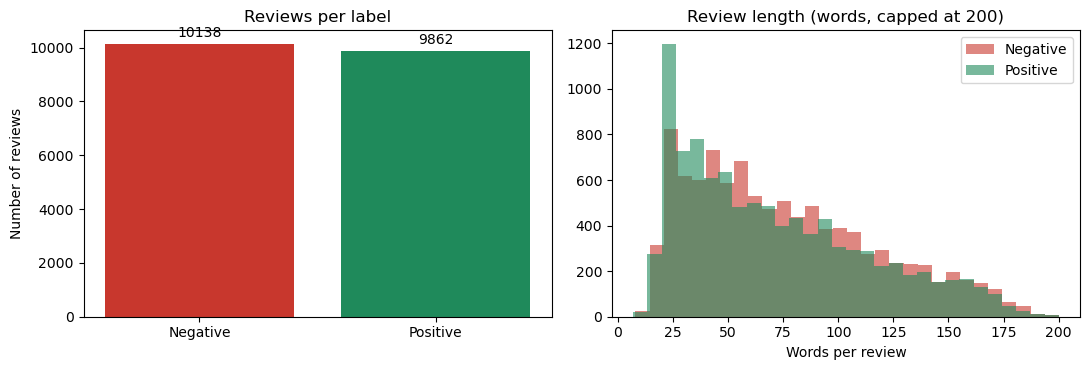

Reproducibility info saved to: amazon_polarity_v2_raw_info.json
SHA-256: 62a6f005a25fc24d4f6b104eea6d4956d534761e0113ca51d94bbf67d482f25e


,review,label
0,"I bought three packs of these disks. They are very cute and have vinal on the front. They play beautifully - that is, if you can burn them! I had to throw out over half of them because they would ...",0
1,"At 60 pages,this is over-priced and not a course for adults. As basic instruction for those 10 and under, it is probably okay. For anyone who even doodles while talking on the phone- forget it!",0
2,"We ordered this boe bot after my son used a version in a robots class he took. The instructions did not correspond well with the bot at all, and we had to play ""guess what to do next"" for most of ...",0


In [42]:
import hashlib
import json
import os
import time
from datetime import datetime
from pathlib import Path

# If huggingface.co is slow or blocked on your network, uncomment ONE mirror line
# BEFORE the datasets import (it only works if set before the import):
# os.environ["HF_ENDPOINT"] = "https://hf-mirror.com"

import datasets
import matplotlib.pyplot as plt
import pandas as pd
from datasets import load_dataset

DATASET = "fancyzhx/amazon_polarity"
SPLIT = "train"          # the official test split stays unused
SEED = 42
SHUFFLE_BUFFER = 10_000
SAMPLE_SIZE = 20_000

project_dir = Path.cwd()
data_dir = project_dir / "data"
data_dir.mkdir(exist_ok=True)

sample_path = data_dir / "amazon_polarity_v2_raw.csv"
info_path = data_dir / "amazon_polarity_v2_raw_info.json"
LABEL_NAMES = {0: "Negative", 1: "Positive"}


def validate(frame):
    """Raise ValueError if the sample is not what we expect."""
    if list(frame.columns) != ["review", "label"]:
        raise ValueError(f"Unexpected columns: {list(frame.columns)}")
    if frame.isna().any().any():
        raise ValueError("The sample contains missing values.")
    if not frame["label"].isin([0, 1]).all():
        raise ValueError("Labels must be 0 or 1.")
    if (frame["review"].astype(str).str.strip() == "").any():
        raise ValueError("The sample contains empty reviews.")
    if len(frame) != SAMPLE_SIZE:
        raise ValueError(f"Expected {SAMPLE_SIZE:,} reviews, found {len(frame):,}.")


def download_sample(attempts=3):
    """Stream a shuffled sample from the training split, with retries."""
    for attempt in range(1, attempts + 1):
        try:
            print(f"Connecting to Amazon Polarity (attempt {attempt}/{attempts})...", flush=True)
            stream = load_dataset(DATASET, split=SPLIT, streaming=True)
            stream = stream.shuffle(seed=SEED, buffer_size=SHUFFLE_BUFFER)

            rows = []
            for item in stream.take(SAMPLE_SIZE):
                rows.append({"review": item["content"], "label": int(item["label"])})
                if len(rows) % 5000 == 0:
                    print(f"Loaded {len(rows):,} reviews...", flush=True)
            return pd.DataFrame(rows)

        except Exception as error:  # network, timeout, hub errors...
            print(f"Attempt {attempt} failed: {type(error).__name__}: {error}")
            if attempt == attempts:
                raise RuntimeError(
                    "Could not download the sample. Check your internet connection, "
                    "or set a Hugging Face mirror (see the HF_ENDPOINT line at the top)."
                ) from error
            time.sleep(5 * attempt)


larger_df = None

if sample_path.exists():
    try:
        larger_df = pd.read_csv(sample_path)
        validate(larger_df)
        print("Loaded the existing sample.")
    except (ValueError, pd.errors.ParserError) as error:
        print(f"Existing sample is not valid ({error}). Downloading again...")
        larger_df = None

if larger_df is None:
    larger_df = download_sample()
    validate(larger_df)

    # Write to a temporary file first so a failure never leaves a broken CSV.
    temp_path = sample_path.with_suffix(".tmp")
    larger_df.to_csv(temp_path, index=False)
    temp_path.replace(sample_path)
    print("Sample saved:", sample_path)

#  reproducibility info
checksum = hashlib.sha256(sample_path.read_bytes()).hexdigest()
info = {
    "dataset": DATASET,
    "source_split": SPLIT,
    "rows": len(larger_df),
    "sampling_seed": SEED,
    "shuffle_buffer": SHUFFLE_BUFFER,
    "csv_sha256": checksum,
    "datasets_version": datasets.__version__,
    "pandas_version": pd.__version__,
    "saved": datetime.now().isoformat(timespec="seconds"),
}
info_path.write_text(json.dumps(info, indent=2), encoding="utf-8")

#  summary
print("\nDataset shape:", larger_df.shape)

counts = larger_df["label"].value_counts().sort_index()
balance = pd.DataFrame({
    "Label": [LABEL_NAMES[label] for label in counts.index],
    "Reviews": counts.values,
    "Share": [f"{share:.1%}" for share in counts / len(larger_df)],
}, index=counts.index)
print("\nLabel counts: 0 = Negative, 1 = Positive")
display(balance)

quality = pd.Series({
    "Missing values": int(larger_df.isna().sum().sum()),
    "Empty reviews": int((larger_df["review"].str.strip() == "").sum()),
    "Exact duplicate reviews": int(larger_df["review"].duplicated().sum()),
}, name="Count")
print("Data quality:")
display(quality.to_frame())

larger_df["words"] = larger_df["review"].str.split().str.len()
length_stats = (
    larger_df.groupby("label")["words"]
    .describe()[["mean", "min", "50%", "max"]]
    .rename(index=LABEL_NAMES, columns={"50%": "median"})
    .round(1)
)
print("Words per review:")
display(length_stats)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
bars = axes[0].bar(
    [LABEL_NAMES[label] for label in counts.index],
    counts.values,
    color=["#c8372d", "#1f8a5b"],
)
axes[0].bar_label(bars, padding=3)
axes[0].set_title("Reviews per label")
axes[0].set_ylabel("Number of reviews")

for label in (0, 1):
    axes[1].hist(
        larger_df.loc[larger_df["label"] == label, "words"].clip(upper=200),
        bins=30, alpha=0.6, label=LABEL_NAMES[label],
        color="#c8372d" if label == 0 else "#1f8a5b",
    )
axes[1].set_title("Review length (words, capped at 200)")
axes[1].set_xlabel("Words per review")
axes[1].legend()
fig.tight_layout()
plt.show()

larger_df = larger_df.drop(columns="words")  # keep the original two columns

print("Reproducibility info saved to:", info_path.name)
print("SHA-256:", checksum)

import pandas as pd
with pd.option_context("display.max_colwidth", 200):
    display(larger_df.head(3))

## 4.1 Remove duplicates and conflicting labels




In [43]:
import re
import unicodedata
from pathlib import Path

import pandas as pd

# The version 2 model was trained on 19,993 clean reviews from the 20,000 sample.
EXPECTED_CLEAN = 19_993

# False = same duplicate rule as before (case-insensitive exact match).
# True  = also ignore punctuation and Unicode variants. This can remove more
#         rows and would no longer reproduce the 19,993 figure.
STRICT_KEY = False

LABEL_NAMES = {0: "Negative", 1: "Positive"}

project_dir = Path.cwd()
data_dir = project_dir / "data"
raw_path = data_dir / "amazon_polarity_v2_raw.csv"
if not raw_path.exists():
    raise FileNotFoundError(f"Raw sample not found: {raw_path}")

raw_v2 = pd.read_csv(raw_path)
missing_cols = {"review", "label"} - set(raw_v2.columns)
if missing_cols:
    raise ValueError(f"Missing columns: {sorted(missing_cols)}")

clean_v2 = raw_v2[["review", "label"]].copy()
steps = [("Original rows", len(clean_v2))]


def tidy_spaces(text):
    """Collapse repeated whitespace; keep words and punctuation such as "not"."""
    return re.sub(r"\s+", " ", text).strip()


def make_key(text):
    """Key used only to detect repeated reviews."""
    if not STRICT_KEY:
        return text.casefold()
    text = unicodedata.normalize("NFKC", text).casefold()
    text = re.sub(r"[^\w\s]", " ", text)
    return re.sub(r"\s+", " ", text).strip()


# 1. Missing values.
clean_v2 = clean_v2.dropna(subset=["review", "label"]).copy()
steps.append(("After removing missing values", len(clean_v2)))

# 2. Whitespace cleanup, then empty reviews.
clean_v2["review"] = clean_v2["review"].astype(str).map(tidy_spaces)
clean_v2 = clean_v2[clean_v2["review"] != ""].copy()
steps.append(("After removing empty reviews", len(clean_v2)))

# 3. Labels must be 0 or 1.
bad_labels = ~clean_v2["label"].isin([0, 1])
if bad_labels.any():
    raise ValueError(f"Unexpected labels found in {int(bad_labels.sum())} rows.")
clean_v2["label"] = clean_v2["label"].astype(int)

# 4. Comparison key for detecting repeated reviews.
clean_v2["review_key"] = clean_v2["review"].map(make_key)
clean_v2 = clean_v2[clean_v2["review_key"] != ""].copy()
steps.append(("After removing reviews without words", len(clean_v2)))

# 5. Remove all copies of reviews with contradictory labels (kept for inspection).
label_counts = clean_v2.groupby("review_key")["label"].nunique()
conflicting_keys = label_counts[label_counts > 1].index
conflict_mask = clean_v2["review_key"].isin(conflicting_keys)

conflicts_v2 = clean_v2[conflict_mask].sort_values("review_key")
print("Rows with conflicting labels:", int(conflict_mask.sum()))
if len(conflicts_v2):
    display(conflicts_v2[["review", "label"]].head(10))

clean_v2 = clean_v2.loc[~conflict_mask].copy()
steps.append(("After removing conflicting labels", len(clean_v2)))

# 6. Keep one copy of each remaining review.
duplicate_count = int(clean_v2.duplicated("review_key").sum())
print("Duplicate rows removed:", duplicate_count)

clean_v2 = clean_v2.drop_duplicates("review_key").reset_index(drop=True)
steps.append(("After removing repeated reviews", len(clean_v2)))

#  summary
report = pd.DataFrame(steps, columns=["Step", "Rows"])
report["Removed"] = (-report["Rows"].diff()).fillna(0).astype(int)
print("\nCleaning summary:")
display(report)

print("Original reviews:", len(raw_v2))
print("Clean reviews:", len(clean_v2))

if len(raw_v2) == 20_000 and not STRICT_KEY:
    if len(clean_v2) == EXPECTED_CLEAN:
        print(f"Matches the {EXPECTED_CLEAN:,} clean reviews used for the version 2 model.")
    else:
        print(f"Note: version 2 used {EXPECTED_CLEAN:,} clean reviews, this run has "
              f"{len(clean_v2):,}. Check that the raw sample is the same file.")

final_counts = clean_v2["label"].value_counts().sort_index()
final_balance = pd.DataFrame({
    "Label": [LABEL_NAMES[label] for label in final_counts.index],
    "Reviews": final_counts.values,
    "Share": [f"{share:.1%}" for share in final_counts / len(clean_v2)],
}, index=final_counts.index)
print("\nLabels after cleaning:")
display(final_balance)

# Save the cleaned data next to the raw file for later notebooks.
clean_path = data_dir / "amazon_polarity_v2_clean.csv"
clean_v2[["review", "label"]].to_csv(clean_path, index=False, encoding="utf-8")
print("Saved:", clean_path)

Rows with conflicting labels: 0
Duplicate rows removed: 7

Cleaning summary:


,Step,Rows,Removed
0,Original rows,20000,0
1,After removing missing values,20000,0
2,After removing empty reviews,20000,0
3,After removing reviews without words,20000,0
4,After removing conflicting labels,20000,0
5,After removing repeated reviews,19993,7


Original reviews: 20000
Clean reviews: 19993
Matches the 19,993 clean reviews used for the version 2 model.

Labels after cleaning:


,Label,Reviews,Share
label,,,
0,Negative,10131,50.7%
1,Positive,9862,49.3%


Saved: C:\Users\Mohammad\Desktop\Fith_Semister\Profesional Training\assignment\PT22026\ali081\data\amazon_polarity_v2_clean.csv


## 4.2 Stratified development splits




,Set,Reviews,Share of data,Negative,Positive,Positive share
0,Training,15994,80.0%,8105,7889,49.3%
1,Validation,3999,20.0%,2026,1973,49.3%


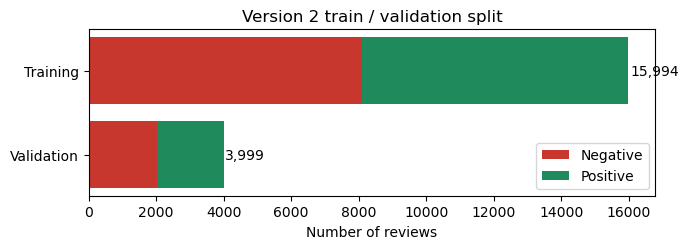


Overlap with earlier data files:


,Earlier file,Reviews in file,Shared with v2 training,Shared with v2 validation
0,train.csv,688,0,0
1,validation.csv,147,0,0
2,test.csv,148,0,0
3,test_v2.csv,5000,0,0



Version 2 splits saved.
Verified: no identical normalized reviews shared between sets.


In [44]:
import json

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.model_selection import train_test_split

SEED = 42
VAL_SIZE = 0.20

assert clean_v2["review_key"].is_unique, "Duplicate review keys found: clean the data first."

train_v2, val_v2 = train_test_split(
    clean_v2,
    test_size=VAL_SIZE,
    random_state=SEED,
    stratify=clean_v2["label"],
)
train_v2 = train_v2.reset_index(drop=True)
val_v2 = val_v2.reset_index(drop=True)

#  checks
assert len(train_v2) + len(val_v2) == len(clean_v2), "Some reviews were lost in the split."
assert set(train_v2["review_key"]).isdisjoint(set(val_v2["review_key"])), \
    "Identical normalized reviews cross the training/validation split."

#  summary
parts = [("Training", train_v2), ("Validation", val_v2)]
summary_v2 = pd.DataFrame([
    {
        "Set": name,
        "Reviews": len(part),
        "Share of data": f"{len(part) / len(clean_v2):.1%}",
        "Negative": int((part["label"] == 0).sum()),
        "Positive": int((part["label"] == 1).sum()),
        "Positive share": f"{(part['label'] == 1).mean():.1%}",
    }
    for name, part in parts
])
display(summary_v2)

fig, ax = plt.subplots(figsize=(7, 2.6))
names = [name for name, _ in parts]
negatives = [int((part["label"] == 0).sum()) for _, part in parts]
positives = [int((part["label"] == 1).sum()) for _, part in parts]
ax.barh(names, negatives, color="#c8372d", label="Negative")
ax.barh(names, positives, left=negatives, color="#1f8a5b", label="Positive")
for i, (neg, pos) in enumerate(zip(negatives, positives)):
    ax.text(neg + pos + 50, i, f"{neg + pos:,}", va="center")
ax.invert_yaxis()
ax.set_xlabel("Number of reviews")
ax.set_title("Version 2 train / validation split")
ax.legend(loc="lower right")
fig.tight_layout()
plt.show()

#  optional overlap report with other data files
# Reports (does not stop) how many reviews also appear in earlier files, if present.
def keys_of(path):
    frame = pd.read_csv(path)
    return set(frame["review"].dropna().astype(str).str.replace(r"\s+", " ", regex=True)
               .str.strip().str.casefold())


overlap_rows = []
for filename in ["train.csv", "validation.csv", "test.csv", "test_v2.csv"]:
    path = data_dir / filename
    if path.exists():
        other = keys_of(path)
        overlap_rows.append({
            "Earlier file": filename,
            "Reviews in file": len(other),
            "Shared with v2 training": len(other & set(train_v2["review_key"])),
            "Shared with v2 validation": len(other & set(val_v2["review_key"])),
        })
if overlap_rows:
    print("\nOverlap with earlier data files:")
    display(pd.DataFrame(overlap_rows))

#  save
# Separate filenames preserve the original experiment.
train_v2[["review", "label"]].to_csv(data_dir / "train_v2.csv", index=False)
val_v2[["review", "label"]].to_csv(data_dir / "validation_v2.csv", index=False)

split_info = {
    "seed": SEED,
    "validation_fraction": VAL_SIZE,
    "stratified_by": "label",
    "total_reviews": len(clean_v2),
    "training_reviews": len(train_v2),
    "validation_reviews": len(val_v2),
}
(data_dir / "split_info_v2.json").write_text(json.dumps(split_info, indent=2), encoding="utf-8")

print("\nVersion 2 splits saved.")
print("Verified: no identical normalized reviews shared between sets.")

## 4.3 Candidate comparison




Training reviews: 15,994 | Validation reviews: 3,999
Training Naive Bayes...
Completed in 7.4 seconds.

Training Logistic Regression...
Completed in 4.6 seconds.



,Model,Train accuracy,Validation accuracy,Overfit gap,Macro precision,Macro recall,Macro F1,CV Macro F1 (mean),CV Macro F1 (std),Training seconds
0,Logistic Regression,0.9987,0.8800,0.1188,0.8800,0.8799,0.8799,0.8747,0.0055,4.5527
1,Naive Bayes,0.9640,0.8615,0.1026,0.8624,0.8611,0.8613,0.8650,0.0066,7.3620


Best on validation: Logistic Regression (Macro F1 0.8799).
One validation review = 0.025% of accuracy.
Lead over the runner-up: 0.0187 Macro F1.


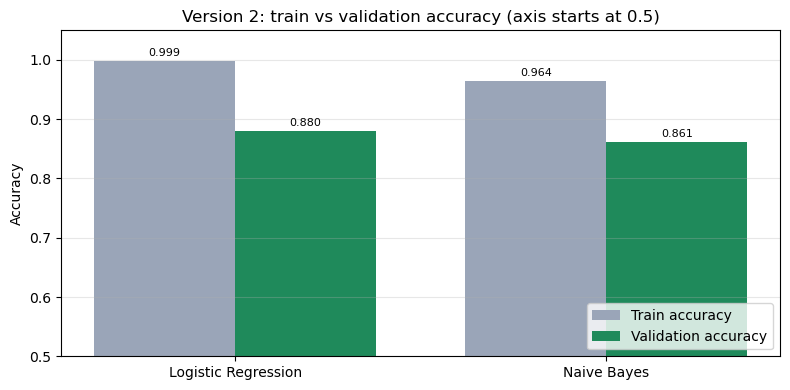


Words with the strongest weights:


,Strongest negative,Weight (neg),Strongest positive,Weight (pos)
0,not,-13.40,great,16.57
1,boring,-10.86,excellent,9.64
2,worst,-9.43,perfect,8.42
3,poor,-8.86,best,8.36
4,disappointed,-8.59,good,7.77
5,waste,-8.28,love,7.57
6,terrible,-7.73,easy,6.28
7,the worst,-7.71,the best,6.16
8,not worth,-7.67,wonderful,6.14
9,disappointing,-7.49,this is,6.05



Selected candidate: Logistic Regression
Version 2 candidate and validation results saved.
Your original app model remains unchanged.


In [45]:
import json
from pathlib import Path
from time import perf_counter

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.base import clone
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline

SEED = 42
RUN_CV = True   # 5-fold cross-validation on the training set (adds some minutes)

project_dir = Path.cwd()
data_dir = project_dir / "data"
results_dir = project_dir / "results"
models_dir = project_dir / "models"
results_dir.mkdir(exist_ok=True)
models_dir.mkdir(exist_ok=True)


def load_split(name):
    frame = pd.read_csv(data_dir / name).dropna(subset=["review", "label"])
    assert {"review", "label"} <= set(frame.columns), f"{name} needs review and label columns."
    return frame


train_v2 = load_split("train_v2.csv")
val_v2 = load_split("validation_v2.csv")
print(f"Training reviews: {len(train_v2):,} | Validation reviews: {len(val_v2):,}")


def make_pipeline(classifier):
    return Pipeline([
        ("tfidf", TfidfVectorizer(
            lowercase=True,
            ngram_range=(1, 2),
            stop_words=None,
            min_df=2,
            max_features=100000,
            sublinear_tf=True,
        )),
        ("classifier", classifier),
    ])


models_v2 = {
    "Naive Bayes": make_pipeline(MultinomialNB(alpha=0.5)),
    "Logistic Regression": make_pipeline(
        LogisticRegression(C=10.0, solver="liblinear", max_iter=2000, random_state=SEED)
    ),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
X_train, y_train = train_v2["review"], train_v2["label"]
X_val, y_val = val_v2["review"], val_v2["label"]

rows = []
val_predictions = {}

for name, model in models_v2.items():
    print(f"Training {name}...", flush=True)

    cv_mean = cv_std = np.nan
    if RUN_CV:
        scores = cross_val_score(clone(model), X_train, y_train, cv=cv,
                                 scoring="f1_macro", n_jobs=2)
        cv_mean, cv_std = scores.mean(), scores.std()

    start = perf_counter()
    # Vocabulary and model are learned from training reviews only.
    model.fit(X_train, y_train)
    training_seconds = perf_counter() - start

    train_pred = model.predict(X_train)
    val_pred = model.predict(X_val)
    val_predictions[name] = val_pred

    train_acc = accuracy_score(y_train, train_pred)
    val_acc = accuracy_score(y_val, val_pred)

    rows.append({
        "Model": name,
        "Train accuracy": train_acc,
        "Validation accuracy": val_acc,
        "Overfit gap": train_acc - val_acc,
        "Macro precision": precision_score(y_val, val_pred, average="macro", zero_division=0),
        "Macro recall": recall_score(y_val, val_pred, average="macro", zero_division=0),
        "Macro F1": f1_score(y_val, val_pred, average="macro", zero_division=0),
        "CV Macro F1 (mean)": cv_mean,
        "CV Macro F1 (std)": cv_std,
        "Training seconds": training_seconds,
    })
    print(f"Completed in {training_seconds:.1f} seconds.\n")

comparison_v2 = (
    pd.DataFrame(rows)
    .sort_values(["Macro F1", "Validation accuracy"], ascending=False)
    .reset_index(drop=True)
)
display(comparison_v2.round(4))

best = comparison_v2.iloc[0]
print(f"Best on validation: {best['Model']} (Macro F1 {best['Macro F1']:.4f}).")
print(f"One validation review = {1 / len(val_v2):.3%} of accuracy.")
if len(comparison_v2) > 1:
    gap = best["Macro F1"] - comparison_v2.iloc[1]["Macro F1"]
    print(f"Lead over the runner-up: {gap:.4f} Macro F1.")

#  chart
fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(len(comparison_v2))
width = 0.38
train_bars = ax.bar(x - width / 2, comparison_v2["Train accuracy"], width,
                    label="Train accuracy", color="#9aa5b8")
val_bars = ax.bar(x + width / 2, comparison_v2["Validation accuracy"], width,
                  label="Validation accuracy", color="#1f8a5b")
ax.bar_label(train_bars, fmt="%.3f", padding=2, fontsize=8)
ax.bar_label(val_bars, fmt="%.3f", padding=2, fontsize=8)
ax.set_xticks(x)
ax.set_xticklabels(comparison_v2["Model"])
ax.set_ylim(0.5, 1.05)
ax.set_ylabel("Accuracy")
ax.set_title("Version 2: train vs validation accuracy (axis starts at 0.5)")
ax.legend(loc="lower right")
ax.grid(axis="y", alpha=0.3)
fig.tight_layout()
fig.savefig(results_dir / "validation_comparison_v2.png", dpi=200, bbox_inches="tight")
plt.show()

comparison_v2.to_csv(results_dir / "validation_comparison_v2.csv", index=False)

#  save the candidate model
best_name_v2 = best["Model"]
candidate_v2 = models_v2[best_name_v2]
candidate_path = models_dir / "sentiment_v2_candidate.joblib"

joblib.dump(candidate_v2, candidate_path)

# Reload check: the saved file must give identical predictions.
reloaded = joblib.load(candidate_path)
assert (reloaded.predict(X_val) == val_predictions[best_name_v2]).all(), "Saved model differs!"

candidate_info = {
    "candidate": best_name_v2,
    "selection_metric": "validation macro F1",
    "validation_macro_f1": float(best["Macro F1"]),
    "validation_accuracy": float(best["Validation accuracy"]),
    "training_reviews": len(train_v2),
    "validation_reviews": len(val_v2),
    "seed": SEED,
    "scikit_learn_version": sklearn.__version__,
    "classifier_params": {k: str(v) for k, v in candidate_v2.steps[-1][1].get_params().items()},
}
(results_dir / "candidate_v2_info.json").write_text(
    json.dumps(candidate_info, indent=2), encoding="utf-8"
)

# For Logistic Regression: the words with the strongest weights.
classifier = candidate_v2.steps[-1][1]
if hasattr(classifier, "coef_"):
    names = candidate_v2.named_steps["tfidf"].get_feature_names_out()
    weights = classifier.coef_[0]
    order = np.argsort(weights)
    top_words = pd.DataFrame({
        "Strongest negative": names[order[:10]],
        "Weight (neg)": weights[order[:10]].round(2),
        "Strongest positive": names[order[::-1][:10]],
        "Weight (pos)": weights[order[::-1][:10]].round(2),
    })
    print("\nWords with the strongest weights:")
    display(top_words)

print("\nSelected candidate:", best_name_v2)
print("Version 2 candidate and validation results saved.")
print("Your original app model remains unchanged.")

## 4.4 Refit the selected candidate




In [46]:
import hashlib
import json
import shutil
from datetime import datetime
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import sklearn
from sklearn.base import clone

project_dir = Path.cwd()
data_dir = project_dir / "data"
models_dir = project_dir / "models"
results_dir = project_dir / "results"
results_dir.mkdir(exist_ok=True)

candidate_path = models_dir / "sentiment_v2_candidate.joblib"
final_path = models_dir / "sentiment_pipeline_v2.joblib"

if not candidate_path.exists():
    raise FileNotFoundError(f"Candidate model not found: {candidate_path}")


def load_split(name):
    frame = pd.read_csv(data_dir / name).dropna(subset=["review", "label"])
    assert {"review", "label"} <= set(frame.columns), f"{name} needs review and label columns."
    return frame


train_v2 = load_split("train_v2.csv")
val_v2 = load_split("validation_v2.csv")

development_v2 = pd.concat([train_v2, val_v2], ignore_index=True)

# The two sets must not share reviews, and the combined data must have no repeats.
keys = development_v2["review"].astype(str).str.casefold()
assert not keys.duplicated().any(), "Repeated reviews found in the combined data."
assert development_v2["label"].isin([0, 1]).all(), "Unexpected labels found."

candidate_v2 = joblib.load(candidate_path)
final_v2 = clone(candidate_v2)   # same settings, fresh and unfitted

print("Training final version 2 model...", flush=True)
final_v2.fit(development_v2["review"], development_v2["label"])

#  protect the model the app already uses
previous_model = None
if final_path.exists():
    stamp = datetime.now().strftime("%Y%m%d_%H%M%S")
    backup_path = models_dir / f"sentiment_pipeline_v2_backup_{stamp}.joblib"
    shutil.copy2(final_path, backup_path)
    print("Existing model backed up to:", backup_path.name)
    try:
        previous_model = joblib.load(final_path)
    except Exception as error:
        print("Could not load the previous model for comparison:", error)

joblib.dump(final_v2, final_path)

# Reload check: the saved file must give identical predictions.
reloaded = joblib.load(final_path)
sample = development_v2["review"].head(2000)
assert (reloaded.predict(sample) == final_v2.predict(sample)).all(), "Saved model differs!"
print("Reload check passed.")

if previous_model is not None:
    same = (previous_model.predict(development_v2["review"]) ==
            final_v2.predict(development_v2["review"])).mean()
    print(f"Agreement with the previous saved model: {same:.2%} of the training reviews.")
    if same < 1.0:
        print("The new model differs from the previous one. If your app and report "
              "quote results for the old model, re-run the test evaluation.")

#  quick sanity predictions
examples = [
    "This headset works perfectly. I love it.",
    "The charger broke after one day. Terrible quality.",
]
positive_col = list(final_v2.classes_).index(1)
for text, probs in zip(examples, final_v2.predict_proba(examples)):
    print(f"  {probs[positive_col]:.1%} positive  <-  {text}")

#  metadata
checksum = hashlib.sha256(final_path.read_bytes()).hexdigest()
info = {
    "model_file": final_path.name,
    "model_sha256": checksum,
    "classifier": type(final_v2.steps[-1][1]).__name__,
    "classifier_params": {k: str(v) for k, v in final_v2.steps[-1][1].get_params().items()},
    "training_reviews": len(development_v2),
    "from_training_split": len(train_v2),
    "from_validation_split": len(val_v2),
    "positive_share": float((development_v2["label"] == 1).mean()),
    "scikit_learn_version": sklearn.__version__,
    "trained": datetime.now().isoformat(timespec="seconds"),
    "note": "Fitted on training + validation data. Evaluate once on the untouched test set.",
}
(results_dir / "final_v2_info.json").write_text(json.dumps(info, indent=2), encoding="utf-8")

print("\nTraining reviews:", len(development_v2))
print("Saved:", final_path.name)
print("SHA-256:", checksum)

Training final version 2 model...
Existing model backed up to: sentiment_pipeline_v2_backup_20261112_162415.joblib
Reload check passed.
Agreement with the previous saved model: 100.00% of the training reviews.
  99.8% positive  <-  This headset works perfectly. I love it.
  1.5% positive  <-  The charger broke after one day. Terrible quality.

Training reviews: 19993
Saved: sentiment_pipeline_v2.joblib
SHA-256: b27248bc2bb352882a7ce1a4e3b69ec3e739b4e8b0b06f8ccea35357d169b256


## 5. Independent test sample and overlap checks

Use the official test split and remove normalized exact matches against development data and the earlier UCI test set. This check does not exclude every possible near-duplicate.


In [47]:
import hashlib
import json
import time
from datetime import datetime
from pathlib import Path

# If huggingface.co is slow or blocked on your network, uncomment ONE mirror line
# BEFORE the datasets import (it only works if set before the import):
# import os; os.environ["HF_ENDPOINT"] = "https://hf-mirror.com"

import datasets
import pandas as pd
from datasets import load_dataset

DATASET = "fancyzhx/amazon_polarity"
SPLIT = "test"                 # the official test split, never used for training
SEED = 123
SHUFFLE_BUFFER = 10_000
SAMPLE_SIZE = 5_000

# False keeps the exact exclusion rule used for the reported test results.
# True also excludes texts from the raw 20,000 training sample that were dropped
# during cleaning (this can change the final test set and its scores).
EXCLUDE_RAW_TRAINING_TEXTS = False

project_dir = Path.cwd()
data_dir = project_dir / "data"
data_dir.mkdir(exist_ok=True)

raw_test_path = data_dir / "amazon_test_v2_raw.csv"
final_test_path = data_dir / "test_v2.csv"
info_path = data_dir / "test_v2_info.json"
LABEL_NAMES = {0: "Negative", 1: "Positive"}


def download_test_sample(attempts=3):
    for attempt in range(1, attempts + 1):
        try:
            print(f"Downloading test sample (attempt {attempt}/{attempts})...", flush=True)
            stream = load_dataset(DATASET, split=SPLIT, streaming=True)
            stream = stream.shuffle(seed=SEED, buffer_size=SHUFFLE_BUFFER)

            rows = []
            for item in stream.take(SAMPLE_SIZE):
                rows.append({"review": item["content"], "label": int(item["label"])})
                if len(rows) % 1000 == 0:
                    print(f"Loaded {len(rows):,} reviews...", flush=True)
            return pd.DataFrame(rows)
        except Exception as error:
            print(f"Attempt {attempt} failed: {type(error).__name__}: {error}")
            if attempt == attempts:
                raise RuntimeError(
                    "Could not download the test sample. Check your connection or set "
                    "a Hugging Face mirror (see the HF_ENDPOINT line at the top)."
                ) from error
            time.sleep(5 * attempt)


raw_test_v2 = None
if raw_test_path.exists():
    try:
        raw_test_v2 = pd.read_csv(raw_test_path)
        assert list(raw_test_v2.columns) == ["review", "label"], "unexpected columns"
        assert len(raw_test_v2) == SAMPLE_SIZE, f"expected {SAMPLE_SIZE:,} rows"
        print("Loaded saved test sample.")
    except (AssertionError, pd.errors.ParserError) as error:
        print(f"Saved test sample is not valid ({error}). Downloading again...")
        raw_test_v2 = None

if raw_test_v2 is None:
    raw_test_v2 = download_test_sample()
    if len(raw_test_v2) != SAMPLE_SIZE:
        raise RuntimeError("The test sample download was incomplete.")
    temp_path = raw_test_path.with_suffix(".tmp")
    raw_test_v2.to_csv(temp_path, index=False)
    temp_path.replace(raw_test_path)       # never leaves a half-written file
    print("Test sample saved:", raw_test_path)


def normalize_reviews(series):
    return (
        series.fillna("")
        .astype(str)
        .str.replace(r"\s+", " ", regex=True)
        .str.strip()
        .str.casefold()
    )


#  texts that must not be in the test set
source_files = {
    "Version 2 training": "train_v2.csv",
    "Version 2 validation": "validation_v2.csv",
    "Old training": "train.csv",
    "Old validation": "validation.csv",
    "Old test": "test.csv",
}
missing = [name for name in source_files.values() if not (data_dir / name).exists()]
if missing:
    raise FileNotFoundError(f"Needed to exclude seen reviews, but missing: {missing}")

known_sources = {
    label: set(normalize_reviews(pd.read_csv(data_dir / name)["review"]))
    for label, name in source_files.items()
}

raw_training_path = data_dir / "amazon_polarity_v2_raw.csv"
raw_training_keys = set()
if raw_training_path.exists():
    raw_training_keys = set(normalize_reviews(pd.read_csv(raw_training_path)["review"]))
    if EXCLUDE_RAW_TRAINING_TEXTS:
        known_sources["Raw 20,000 sample"] = raw_training_keys

known_keys = set().union(*known_sources.values())

#  cleaning
steps = [("Raw test sample", len(raw_test_v2))]

test_v2 = raw_test_v2.dropna(subset=["review", "label"]).copy()
steps.append(("After removing missing values", len(test_v2)))

assert test_v2["label"].isin([0, 1]).all(), "Unexpected labels found."
test_v2["label"] = test_v2["label"].astype(int)

test_v2["review_key"] = normalize_reviews(test_v2["review"])
test_v2 = test_v2[test_v2["review_key"] != ""].copy()
steps.append(("After removing empty reviews", len(test_v2)))

label_counts = test_v2.groupby("review_key")["label"].nunique()
conflicts = label_counts[label_counts > 1].index
test_v2 = test_v2[~test_v2["review_key"].isin(conflicts)]
steps.append(("After removing conflicting labels", len(test_v2)))

test_v2 = test_v2.drop_duplicates("review_key")
steps.append(("After removing repeated reviews", len(test_v2)))

overlap = test_v2["review_key"].isin(known_keys)
print("Previously seen review texts excluded:", int(overlap.sum()))

by_source = pd.DataFrame({
    "Source": list(known_sources),
    "Test reviews also found there": [
        int(test_v2["review_key"].isin(keys).sum()) for keys in known_sources.values()
    ],
})
display(by_source)

if raw_training_keys and not EXCLUDE_RAW_TRAINING_TEXTS:
    dev_keys = known_sources["Version 2 training"] | known_sources["Version 2 validation"]
    only_raw = raw_training_keys - dev_keys   # dropped during cleaning, never trained on
    extra = int(test_v2["review_key"].isin(only_raw).sum())
    print(f"For information: {extra} more test texts appear in the raw 20,000 sample "
          "(removed during cleaning). They are kept, as in the reported results.")

test_v2 = test_v2.loc[~overlap].reset_index(drop=True)
steps.append(("After excluding previously seen texts", len(test_v2)))

assert set(test_v2["review_key"]).isdisjoint(known_keys)
assert test_v2["label"].nunique() == 2, "Test set needs both classes."

#  summary
report = pd.DataFrame(steps, columns=["Step", "Rows"])
report["Removed"] = (-report["Rows"].diff()).fillna(0).astype(int)
print("\nCleaning summary:")
display(report)

counts = test_v2["label"].value_counts().sort_index()
balance = pd.DataFrame({
    "Label": [LABEL_NAMES[label] for label in counts.index],
    "Reviews": counts.values,
    "Share": [f"{share:.1%}" for share in counts / len(test_v2)],
}, index=counts.index)
print("Final test reviews:", len(test_v2))
display(balance)

if len(test_v2) != SAMPLE_SIZE:
    print(f"Note: the final test set has {len(test_v2):,} reviews, not {SAMPLE_SIZE:,}. "
          "If your app text says 'a sample of 5,000', update it to the real number.")

#  save
test_v2.to_csv(final_test_path, index=False)

checksum = hashlib.sha256(final_test_path.read_bytes()).hexdigest()
info = {
    "dataset": DATASET,
    "source_split": SPLIT,
    "sampling_seed": SEED,
    "shuffle_buffer": SHUFFLE_BUFFER,
    "raw_reviews": len(raw_test_v2),
    "final_test_reviews": len(test_v2),
    "excluded_previously_seen": int(overlap.sum()),
    "extra_raw_training_exclusion": EXCLUDE_RAW_TRAINING_TEXTS,
    "test_csv_sha256": checksum,
    "datasets_version": datasets.__version__,
    "pandas_version": pd.__version__,
    "saved": datetime.now().isoformat(timespec="seconds"),
}
info_path.write_text(json.dumps(info, indent=2), encoding="utf-8")
print("Saved:", final_test_path.name, "and", info_path.name)

Loaded saved test sample.
Previously seen review texts excluded: 0


,Source,Test reviews also found there
0,Version 2 training,0
1,Version 2 validation,0
2,Old training,0
3,Old validation,0
4,Old test,0


For information: 0 more test texts appear in the raw 20,000 sample (removed during cleaning). They are kept, as in the reported results.

Cleaning summary:


,Step,Rows,Removed
0,Raw test sample,5000,0
1,After removing missing values,5000,0
2,After removing empty reviews,5000,0
3,After removing conflicting labels,5000,0
4,After removing repeated reviews,5000,0
5,After excluding previously seen texts,5000,0


Final test reviews: 5000


,Label,Reviews,Share
label,,,
0,Negative,2416,48.3%
1,Positive,2584,51.7%


Saved: test_v2.csv and test_v2_info.json


## 5.1 Compare both model versions

Both training data and classifier changed. The improvement cannot be attributed to the classifier alone. Do not use this test sample to choose further model settings.


,Model,Test reviews,Test accuracy,Accuracy 95% CI low,Accuracy 95% CI high,Test Macro F1,Macro precision,Macro recall
0,Version 1 - original Naive Bayes,5000,0.7086,0.6956,0.7210,0.7055,0.7254,0.7128
1,Version 2 - Logistic Regression,5000,0.8756,0.8666,0.8852,0.8754,0.8756,0.8752



Paired comparison on the same test reviews:


,Reviews
"v2 fixed (v1 wrong, v2 right)",1123
"v2 broke (v1 right, v2 wrong)",288
both correct,3255
both wrong,334



Version 1 - original Naive Bayes classification report:

              precision    recall  f1-score   support

    Negative     0.6549    0.8390    0.7356      2416
    Positive     0.7958    0.5867    0.6754      2584

    accuracy                         0.7086      5000
   macro avg     0.7254    0.7128    0.7055      5000
weighted avg     0.7277    0.7086    0.7045      5000


Version 2 - Logistic Regression classification report:

              precision    recall  f1-score   support

    Negative     0.8766    0.8642    0.8704      2416
    Positive     0.8747    0.8862    0.8804      2584

    accuracy                         0.8756      5000
   macro avg     0.8756    0.8752    0.8754      5000
weighted avg     0.8756    0.8756    0.8756      5000



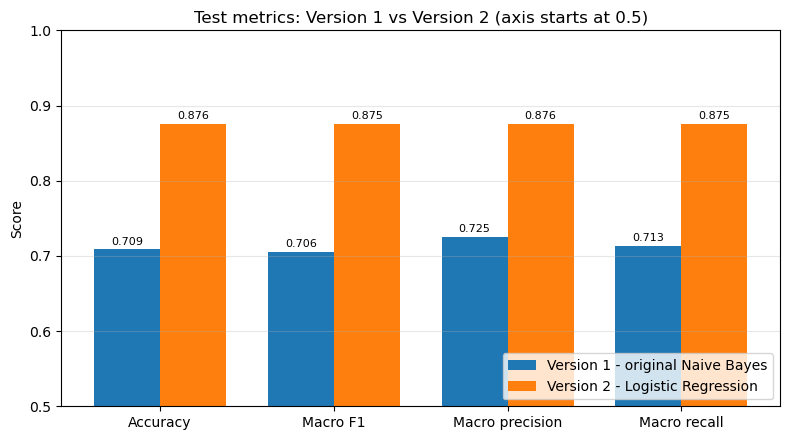

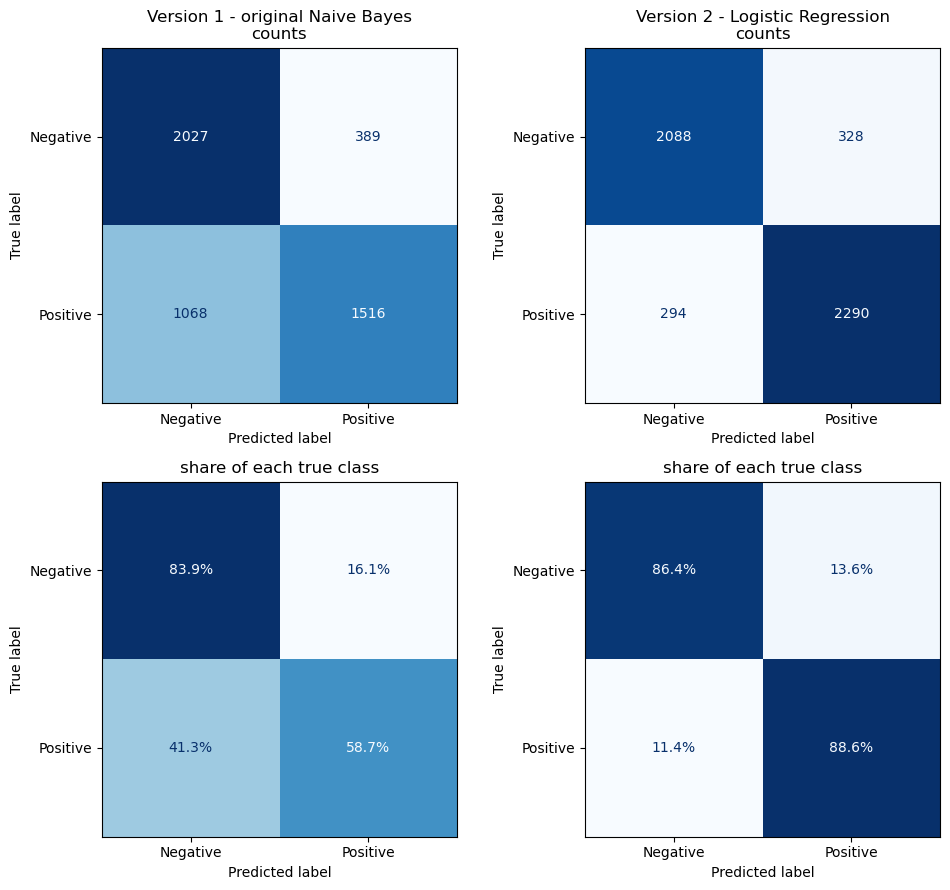

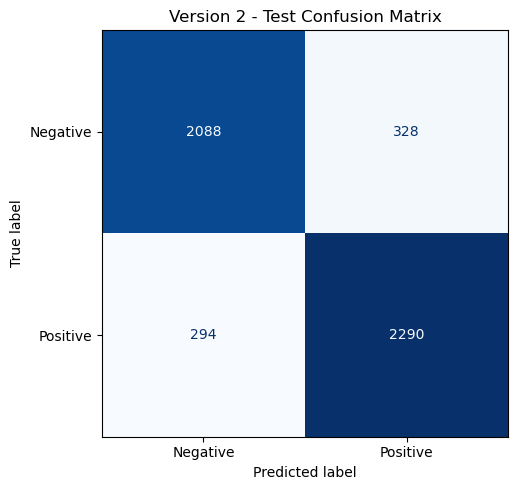


Version 2 made 622 mistakes out of 5000 reviews.
Most confident mistakes:


,review,true,v1_prediction,v2_prediction,v2_p_positive,v2_confidence
1341,I watched the movie on Cartoon Network about t...,Negative,Positive,Positive,0.997993,0.997993
886,This is a GREAT book! I was thrilled to find i...,Negative,Positive,Positive,0.997524,0.997524
1736,The movie wasn't as horrible as some make it o...,Positive,Negative,Negative,0.005464,0.994536
2746,I have used a Dazey and it worked great. The M...,Negative,Positive,Positive,0.993388,0.993388
3416,"The bulb seems ok, the batteries have power, b...",Positive,Negative,Negative,0.010371,0.989629
3735,This is perfect for making ice tea. Blends wel...,Negative,Positive,Positive,0.988085,0.988085
56,I do not intend to review content here. This n...,Positive,Negative,Negative,0.015748,0.984252
4243,Good book.Good shape.Fits my needs on this sub...,Negative,Positive,Positive,0.982943,0.982943
817,who ever alblum was lame ur lame to that dude ...,Positive,Negative,Negative,0.017571,0.982429
767,This is quite a neat little book on gay movies...,Negative,Positive,Positive,0.980442,0.980442



Test results saved to: C:\Users\Mohammad\Desktop\Fith_Semister\Profesional Training\assignment\PT22026\ali081\results


In [27]:
import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    classification_report,
    ConfusionMatrixDisplay,
)

#settings
LABELS = [0, 1]
LABEL_NAMES = ["Negative", "Positive"]
results_dir.mkdir(parents=True, exist_ok=True)

original_model = joblib.load(models_dir / "sentiment_pipeline.joblib")

# short key -> (display name, fitted pipeline)
models_to_evaluate = {
    "v1": ("Version 1 - original Naive Bayes", original_model),
    "v2": ("Version 2 - Logistic Regression", final_v2),
}

X_test = test_v2["review"]
y_test = test_v2["label"].to_numpy()

#Predict once per model and reuse everywhere below.
predictions = {key: pipe.predict(X_test) for key, (_, pipe) in models_to_evaluate.items()}


def accuracy_ci(y_true, y_pred, n_boot=1000, seed=42):
    """95% bootstrap confidence interval for accuracy."""
    rng = np.random.default_rng(seed)
    correct = (y_true == y_pred).astype(float)
    picks = rng.integers(0, len(correct), size=(n_boot, len(correct)))
    means = correct[picks].mean(axis=1)
    return np.percentile(means, [2.5, 97.5])


# 1.comparison table
rows = []
for key, (name, _) in models_to_evaluate.items():
    pred = predictions[key]
    low, high = accuracy_ci(y_test, pred)
    rows.append({
        "Model": name,
        "Test reviews": len(y_test),
        "Test accuracy": accuracy_score(y_test, pred),
        "Accuracy 95% CI low": low,
        "Accuracy 95% CI high": high,
        "Test Macro F1": f1_score(y_test, pred, average="macro", zero_division=0),
        "Macro precision": precision_score(y_test, pred, average="macro", zero_division=0),
        "Macro recall": recall_score(y_test, pred, average="macro", zero_division=0),
    })

test_comparison = pd.DataFrame(rows)
display(test_comparison.round(4))
test_comparison.to_csv(results_dir / "test_comparison_v2.csv", index=False)

#2.paired comparison (v1 vs v2)
v1_ok = predictions["v1"] == y_test
v2_ok = predictions["v2"] == y_test
paired = pd.DataFrame(
    {
        "Reviews": [
            int((~v1_ok & v2_ok).sum()),
            int((v1_ok & ~v2_ok).sum()),
            int((v1_ok & v2_ok).sum()),
            int((~v1_ok & ~v2_ok).sum()),
        ]
    },
    index=[
        "v2 fixed (v1 wrong, v2 right)",
        "v2 broke (v1 right, v2 wrong)",
        "both correct",
        "both wrong",
    ],
)
print("\nPaired comparison on the same test reviews:")
display(paired)

#3.classification reports
for key, (name, _) in models_to_evaluate.items():
    report = classification_report(
        y_test,
        predictions[key],
        labels=LABELS,
        target_names=LABEL_NAMES,
        digits=4,
        zero_division=0,
    )
    print(f"\n{name} classification report:\n")
    print(report)
    (results_dir / f"test_classification_report_{key}.txt").write_text(
        report, encoding="utf-8"
    )

#4.metric comparison bar chart
metrics = ["Test accuracy", "Test Macro F1", "Macro precision", "Macro recall"]
x = np.arange(len(metrics))
width = 0.38

fig, ax = plt.subplots(figsize=(8, 4.5))
for i, (_, row) in enumerate(test_comparison.iterrows()):
    values = [row[m] for m in metrics]
    bars = ax.bar(x + (i - 0.5) * width, values, width, label=row["Model"])
    ax.bar_label(bars, fmt="%.3f", padding=2, fontsize=8)

ax.set_xticks(x)
ax.set_xticklabels(["Accuracy", "Macro F1", "Macro precision", "Macro recall"])
ax.set_ylim(0.5, 1.0)
ax.set_ylabel("Score")
ax.set_title("Test metrics: Version 1 vs Version 2 (axis starts at 0.5)")
ax.legend(loc="lower right")
ax.grid(axis="y", alpha=0.3)
fig.tight_layout()
fig.savefig(results_dir / "test_metric_comparison.png", dpi=200, bbox_inches="tight")
plt.show()

#5.confusion matrices (counts + %)
fig, axes = plt.subplots(2, 2, figsize=(10, 9))
for col, (key, (name, _)) in enumerate(models_to_evaluate.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test, predictions[key], labels=LABELS, display_labels=LABEL_NAMES,
        cmap="Blues", colorbar=False, values_format="d", ax=axes[0, col],
    )
    axes[0, col].set_title(f"{name}\ncounts")

    ConfusionMatrixDisplay.from_predictions(
        y_test, predictions[key], labels=LABELS, display_labels=LABEL_NAMES,
        normalize="true", cmap="Blues", colorbar=False, values_format=".1%",
        ax=axes[1, col],
    )
    axes[1, col].set_title("share of each true class")

fig.tight_layout()
fig.savefig(results_dir / "test_confusion_matrices_v1_v2.png", dpi=200, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test, predictions["v2"], labels=LABELS, display_labels=LABEL_NAMES,
    cmap="Blues", colorbar=False, ax=ax,
)
ax.set_title("Version 2 - Test Confusion Matrix")
fig.tight_layout()
fig.savefig(results_dir / "test_confusion_matrix_v2.png", dpi=200, bbox_inches="tight")
plt.show()

#6.Version 2 error analysis
errors = pd.DataFrame({
    "review": X_test.to_numpy(),
    "true": [LABEL_NAMES[LABELS.index(v)] for v in y_test],
    "v1_prediction": [LABEL_NAMES[LABELS.index(v)] for v in predictions["v1"]],
    "v2_prediction": [LABEL_NAMES[LABELS.index(v)] for v in predictions["v2"]],
})

if hasattr(final_v2, "predict_proba"):
    pos_col = list(final_v2.classes_).index(1)
    errors["v2_p_positive"] = final_v2.predict_proba(X_test)[:, pos_col]
    # How sure v2 was about its (wrong) answer.
    errors["v2_confidence"] = np.maximum(errors["v2_p_positive"], 1 - errors["v2_p_positive"])

v2_errors = errors[predictions["v2"] != y_test]
if "v2_confidence" in v2_errors:
    v2_errors = v2_errors.sort_values("v2_confidence", ascending=False)

v2_errors.to_csv(results_dir / "test_errors_v2.csv", index=False)
print(f"\nVersion 2 made {len(v2_errors)} mistakes out of {len(y_test)} reviews.")
print("Most confident mistakes:")
display(v2_errors.head(10).assign(review=lambda d: d["review"].str.slice(0, 120)))

print("\nTest results saved to:", results_dir)

## 6. Optional reproduction check


In [48]:
import hashlib
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, f1_score

project_dir = Path.cwd()
original_path = project_dir / "models" / "sentiment_pipeline_v2.joblib"
reproduced_path = project_dir / "models" / "sentiment_pipeline_v2_reproduced.joblib"
test_path = project_dir / "data" / "test_v2.csv"

required = [original_path, reproduced_path, test_path]
missing = [str(p) for p in required if not p.exists()]
if missing:
    print("Optional comparison skipped. Missing:", ", ".join(missing))
else:
    def sha256(path):
        return hashlib.sha256(path.read_bytes()).hexdigest()

    original = joblib.load(original_path)
    reproduced = joblib.load(reproduced_path)
    test_data = pd.read_csv(test_path).dropna(subset=["review"])

    checks = []   # (what was compared, same?, detail)

    # 1. Saved files.
    same_file = sha256(original_path) == sha256(reproduced_path)
    checks.append(("Saved files are byte-identical", same_file,
                   "same SHA-256" if same_file else "different SHA-256"))

    # 2. Structure and settings.
    same_steps = [s for s, _ in original.steps] == [s for s, _ in reproduced.steps]
    checks.append(("Pipeline steps", same_steps, " -> ".join(s for s, _ in original.steps)))

    tfidf_a, tfidf_b = original.named_steps["tfidf"], reproduced.named_steps["tfidf"]
    clf_a, clf_b = original.steps[-1][1], reproduced.steps[-1][1]
    checks.append(("TF-IDF settings", tfidf_a.get_params() == tfidf_b.get_params(), ""))
    checks.append(("Classifier settings", clf_a.get_params() == clf_b.get_params(),
                   type(clf_a).__name__))

    # 3. What the models learned.
    same_vocab = tfidf_a.vocabulary_ == tfidf_b.vocabulary_
    checks.append(("Vocabulary", same_vocab, f"{len(tfidf_a.vocabulary_):,} features"))

    if same_vocab and hasattr(clf_a, "coef_") and hasattr(clf_b, "coef_"):
        weight_diff = float(np.abs(clf_a.coef_ - clf_b.coef_).max())
        intercept_diff = float(np.abs(clf_a.intercept_ - clf_b.intercept_).max())
        checks.append(("Learned weights (max difference)", weight_diff < 1e-9, f"{weight_diff:.2e}"))
        checks.append(("Intercept (max difference)", intercept_diff < 1e-9, f"{intercept_diff:.2e}"))

    # 4. Behaviour on the test reviews.
    texts = test_data["review"]
    pred_a, pred_b = original.predict(texts), reproduced.predict(texts)
    prob_a, prob_b = original.predict_proba(texts), reproduced.predict_proba(texts)

    agree = pred_a == pred_b
    prob_diff = float(np.abs(prob_a - prob_b).max())
    checks.append(("Predictions on test reviews", bool(agree.all()),
                   f"{int(agree.sum()):,} of {len(texts):,} match"))
    checks.append(("Probabilities (max difference)", prob_diff < 1e-9, f"{prob_diff:.2e}"))

    table = pd.DataFrame(checks, columns=["Check", "Same?", "Detail"])
    table["Same?"] = table["Same?"].map({True: "✅ yes", False: "❌ no"})
    display(table)

    print(f"Prediction agreement: {agree.mean():.2%}")
    print("Matching predictions:", int(agree.sum()), "of", len(test_data))

    # 5. Test scores of both models, if labels are available.
    if "label" in test_data.columns and test_data["label"].isin([0, 1]).all():
        y = test_data["label"]
        scores = pd.DataFrame({
            "Model": ["Original", "Reproduced"],
            "Test accuracy": [accuracy_score(y, pred_a), accuracy_score(y, pred_b)],
            "Test Macro F1": [f1_score(y, pred_a, average="macro"),
                              f1_score(y, pred_b, average="macro")],
        })
        display(scores.round(4))

    # 6. Verdict.
    others_ok = all(ok for name, ok, _ in checks if name != "Saved files are byte-identical")
    if others_ok and agree.all():
        print("\nVerdict: the reproduced model is functionally identical to the original.")
    elif agree.all():
        print("\nVerdict: same predictions, but some settings or weights differ. See the table.")
    else:
        print("\nVerdict: the models disagree on some reviews.")
        differences = test_data.loc[~agree, ["review"]].copy()
        differences["Original"] = pred_a[~agree]
        differences["Reproduced"] = pred_b[~agree]
        differences["Original P(positive)"] = prob_a[~agree][:, list(original.classes_).index(1)].round(3)
        differences["Reproduced P(positive)"] = prob_b[~agree][:, list(reproduced.classes_).index(1)].round(3)
        with pd.option_context("display.max_colwidth", 120):
            display(differences.head(10))

,Check,Same?,Detail
0,Saved files are byte-identical,❌ no,different SHA-256
1,Pipeline steps,✅ yes,tfidf -> classifier
2,TF-IDF settings,✅ yes,
3,Classifier settings,✅ yes,LogisticRegression
4,Vocabulary,✅ yes,"100,000 features"
5,Learned weights (max difference),✅ yes,0.00e+00
6,Intercept (max difference),✅ yes,0.00e+00
7,Predictions on test reviews,✅ yes,"5,000 of 5,000 match"
8,Probabilities (max difference),✅ yes,0.00e+00


Prediction agreement: 100.00%
Matching predictions: 5000 of 5000


,Model,Test accuracy,Test Macro F1
0,Original,0.8756,0.8754
1,Reproduced,0.8756,0.8754



Verdict: the reproduced model is functionally identical to the original.


## 7. Results and limitations

On the recorded common test sample of 5,000 reviews, the original Naive Bayes model achieved **70.86% accuracy** and version 2 Logistic Regression achieved **87.56% accuracy**, with **0.8754 macro F1**. The accuracy difference is **16.70 percentage points**.

The earlier 81.88% baseline accuracy used a different, smaller UCI test set and is not directly comparable. The version 2 training/validation gap suggests overfitting remains a concern.

- The model has only positive and negative classes; it cannot reliably identify neutral, mixed, or out-of-scope text.
- Probability estimates are not guarantees. The app's 60% uncertainty threshold is a display rule, not a calibrated confidence threshold.
- Negation, sarcasm, and unfamiliar wording can still cause mistakes.
- Prediction agreement on this sample does not establish identical model bytes or identical predictions for all possible inputs.

## 8. Application and maintenance

Maintain the existing `app_v2.py`, `train_v2.py`, `requirements.txt`, and `README.md` separately. Old notebook cells that cloned repositories, made commits, generated files, patched application code, or launched Gradio have been removed from this experiment notebook.

Keep both versions' evaluation results as development evidence. Keep data and trained models excluded from Git. After a meaningful change, test it, review the diff, stage the intended files, and commit from the terminal or VS Code Source Control. Push with `git push fork ali081-work`.
